In [1]:
# ============================================================
# COMMERCECHAIN 360 - EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Pandas Version: 3.0.5
NumPy Version: 2.4.6


In [2]:
PROJECT_PATH = Path.cwd().parent

RAW_PATH = PROJECT_PATH / "data" / "raw"
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"

EDA_REPORT_PATH = PROJECT_PATH / "reports" / "EDA"

EDA_REPORT_PATH.mkdir(parents=True, exist_ok=True)

print("Project Path:", PROJECT_PATH)
print("Processed Data Path:", PROCESSED_PATH)
print("EDA Report Path:", EDA_REPORT_PATH)

Project Path: C:\Users\Shashank\Downloads\Projects\DA\E-commerce Sales, Supply Chain & Delivery Intelligence Platform
Processed Data Path: C:\Users\Shashank\Downloads\Projects\DA\E-commerce Sales, Supply Chain & Delivery Intelligence Platform\data\processed
EDA Report Path: C:\Users\Shashank\Downloads\Projects\DA\E-commerce Sales, Supply Chain & Delivery Intelligence Platform\reports\EDA


In [3]:
# Load all processed datasets

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv",
    dtype={
        "customer_id": "string",
        "customer_unique_id": "string",
        "customer_zip_code_prefix": "string"
    }
)

geolocation = pd.read_csv(
    PROCESSED_PATH / "geolocation_clean.csv",
    dtype={"geolocation_zip_code_prefix": "string"}
)

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv",
    dtype={
        "order_id": "string",
        "product_id": "string",
        "seller_id": "string"
    },
    parse_dates=["shipping_limit_date"]
)

payments = pd.read_csv(
    PROCESSED_PATH / "payments_clean.csv",
    dtype={"order_id": "string"}
)

reviews = pd.read_csv(
    PROCESSED_PATH / "reviews_clean.csv",
    dtype={
        "review_id": "string",
        "order_id": "string"
    },
    parse_dates=[
        "review_creation_date",
        "review_answer_timestamp"
    ]
)

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    dtype={
        "order_id": "string",
        "customer_id": "string"
    },
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv",
    dtype={"product_id": "string"}
)

sellers = pd.read_csv(
    PROCESSED_PATH / "sellers_clean.csv",
    dtype={
        "seller_id": "string",
        "seller_zip_code_prefix": "string"
    }
)

category_translation = pd.read_csv(
    PROCESSED_PATH / "category_translation_clean.csv",
    dtype="string"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
# Load all processed datasets

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv",
    dtype={
        "customer_id": "string",
        "customer_unique_id": "string",
        "customer_zip_code_prefix": "string"
    }
)

geolocation = pd.read_csv(
    PROCESSED_PATH / "geolocation_clean.csv",
    dtype={"geolocation_zip_code_prefix": "string"}
)

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv",
    dtype={
        "order_id": "string",
        "product_id": "string",
        "seller_id": "string"
    },
    parse_dates=["shipping_limit_date"]
)

payments = pd.read_csv(
    PROCESSED_PATH / "payments_clean.csv",
    dtype={"order_id": "string"}
)

reviews = pd.read_csv(
    PROCESSED_PATH / "reviews_clean.csv",
    dtype={
        "review_id": "string",
        "order_id": "string"
    },
    parse_dates=[
        "review_creation_date",
        "review_answer_timestamp"
    ]
)

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    dtype={
        "order_id": "string",
        "customer_id": "string"
    },
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv",
    dtype={"product_id": "string"}
)

sellers = pd.read_csv(
    PROCESSED_PATH / "sellers_clean.csv",
    dtype={
        "seller_id": "string",
        "seller_zip_code_prefix": "string"
    }
)

category_translation = pd.read_csv(
    PROCESSED_PATH / "category_translation_clean.csv",
    dtype="string"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

dataset_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    }
    for name, df in datasets.items()
])

display(dataset_summary)

,Dataset,Rows,Columns
0,Customers,99441,5
1,Geolocation,738332,6
2,Order Items,112650,14
3,Payments,103886,12
4,Reviews,99224,17
5,Orders,99441,19
6,Products,32951,21
7,Sellers,3095,10
8,Category Translation,71,7


COMMERCECHAIN 360 - UNIVARIATE ANALYSIS

1. DATASET OVERVIEW


,Dataset,Rows,Columns,Memory_MB
0,Customers,99441,5,11.03
1,Geolocation,738332,6,60.23
2,Order Items,112650,14,19.12
3,Payments,103886,12,9.99
4,Reviews,99224,17,17.66
5,Orders,99441,19,19.33
6,Products,32951,21,4.93
7,Sellers,3095,10,0.28
8,Category Translation,71,7,0.00



2. NUMERICAL DESCRIPTIVE STATISTICS

Customers - Numerical Statistics


,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
customer_zip_code_prefix,99441.0,35137.47,29797.94,1003.0,11347.0,24416.0,58900.0,99990.0,0,0.78,-0.79



Geolocation - Numerical Statistics


,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
geolocation_zip_code_prefix,738332.0,38316.09,30632.50,1001.00,12600.00,29144.00,65950.00,99990.00,0,0.62,-1.04
geolocation_lat,738332.0,-21.00,5.89,-36.61,-23.60,-22.87,-19.92,45.07,0,1.48,2.46
geolocation_lng,738332.0,-46.46,4.39,-101.47,-48.87,-46.65,-43.84,121.11,0,-0.04,5.00


... (43 outputs left out)

,Category,Count
0,health_beauty,1
1,computers_accessories,1
2,auto,1
3,bed_bath_table,1
4,furniture_decor,1
5,sports_leisure,1
6,perfumery,1
7,housewares,1
8,telephony,1
9,watches_gifts,1



Category Translation - data_quality_status


,Category,Count
0,Valid,71



4. NUMERICAL DISTRIBUTION PLOTS


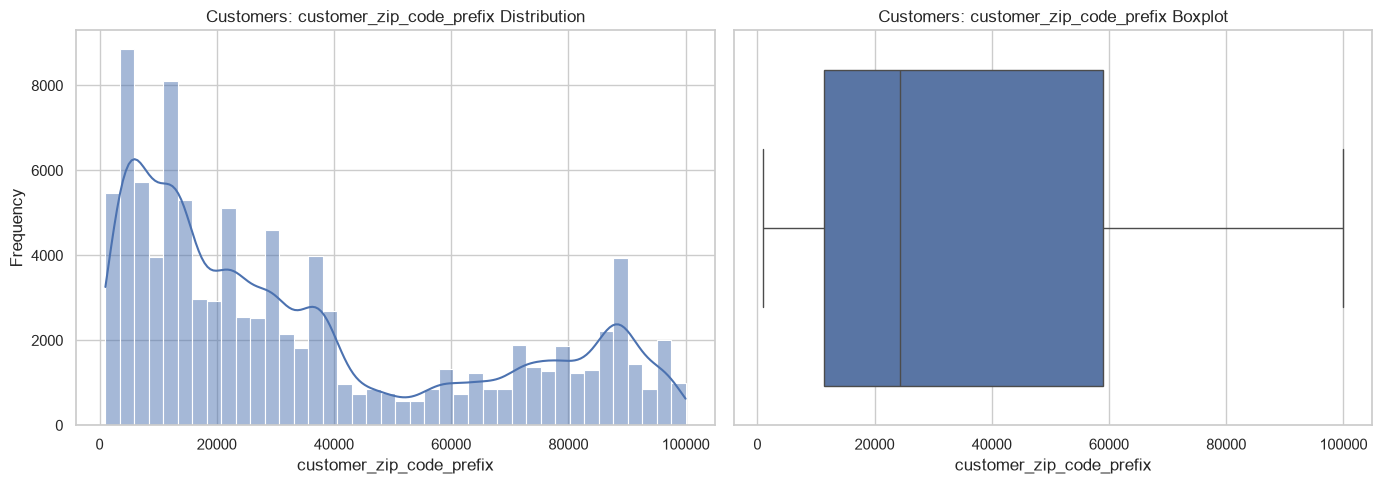

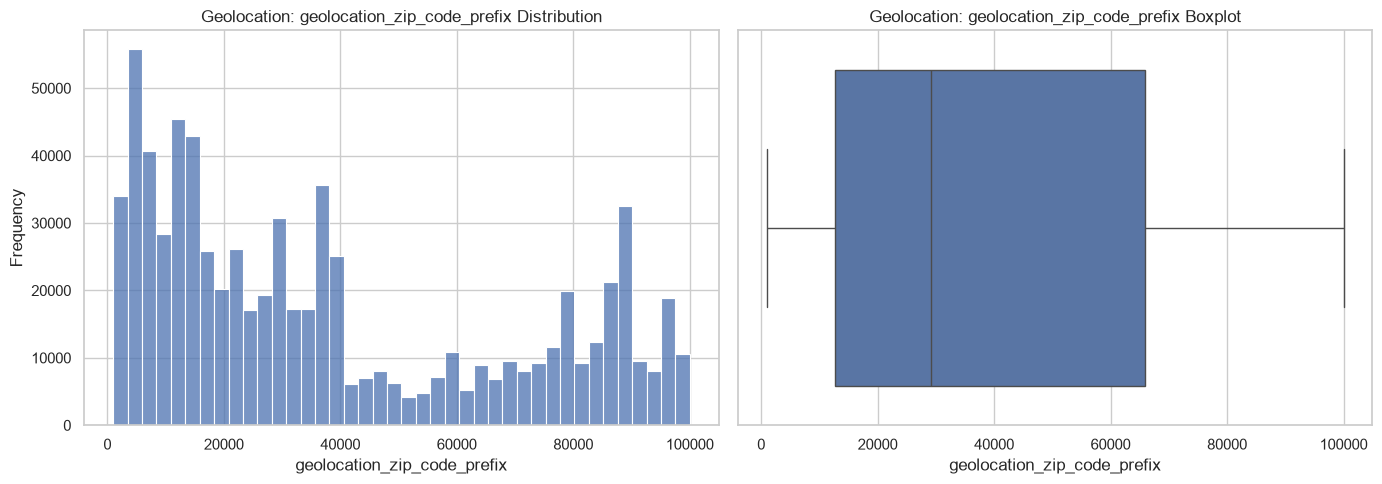

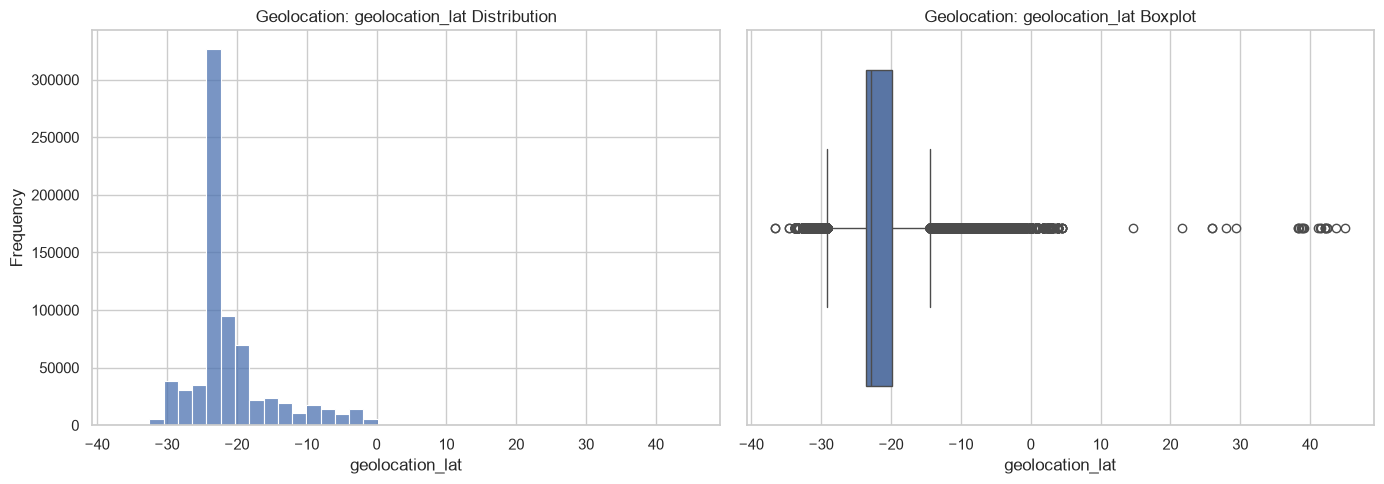

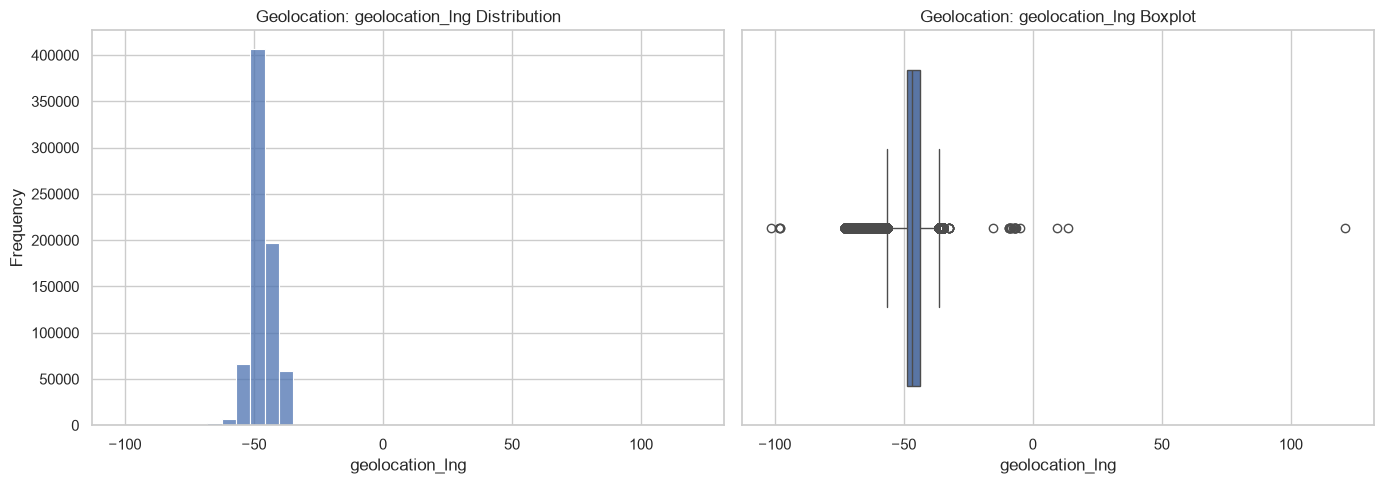

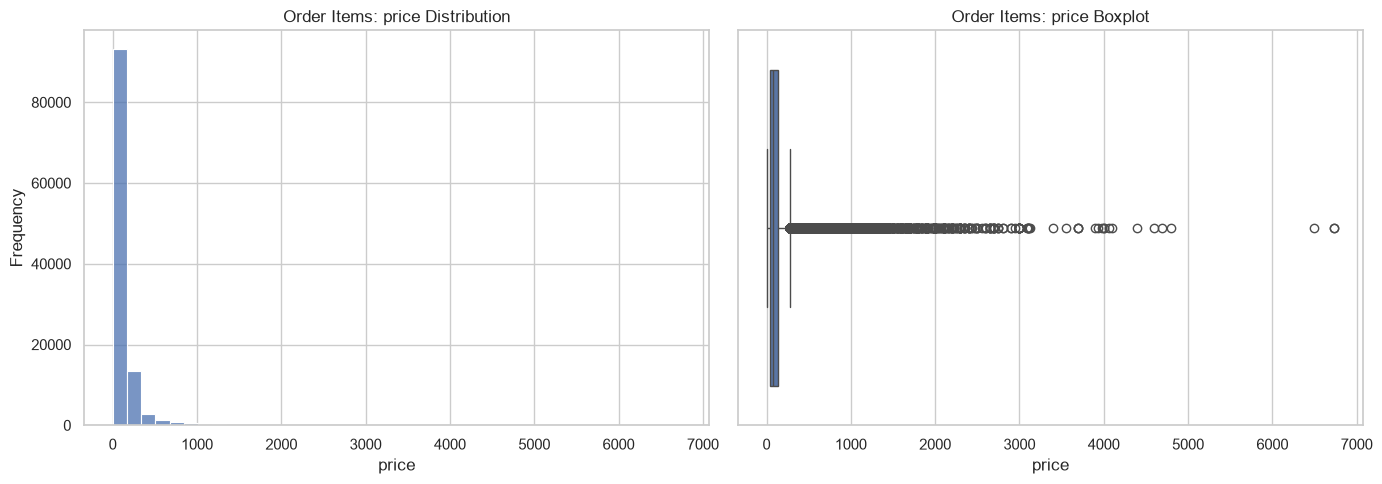

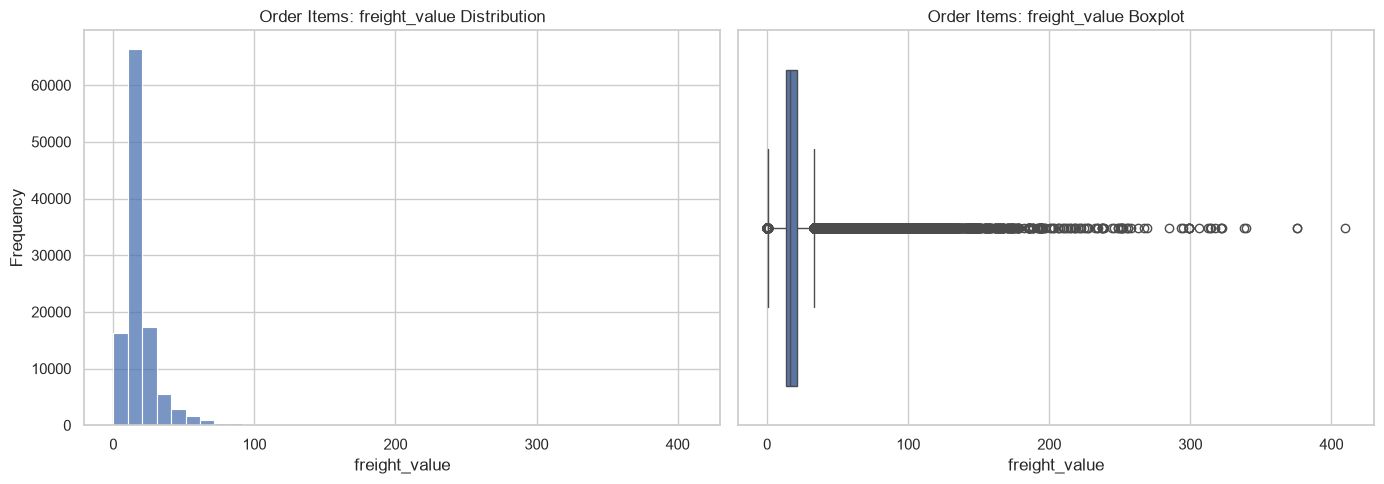

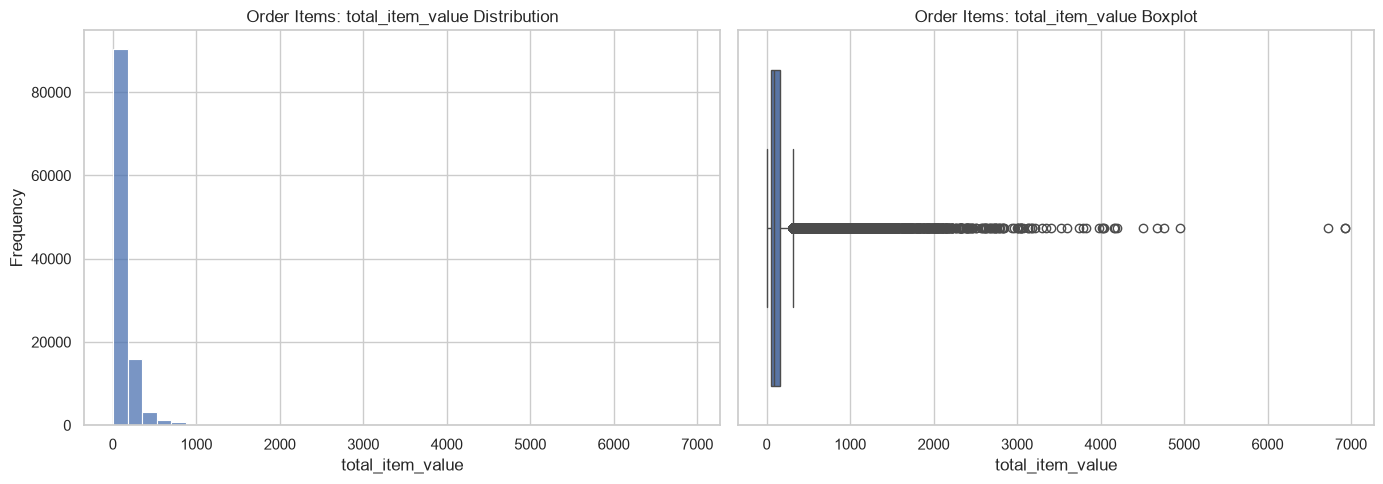

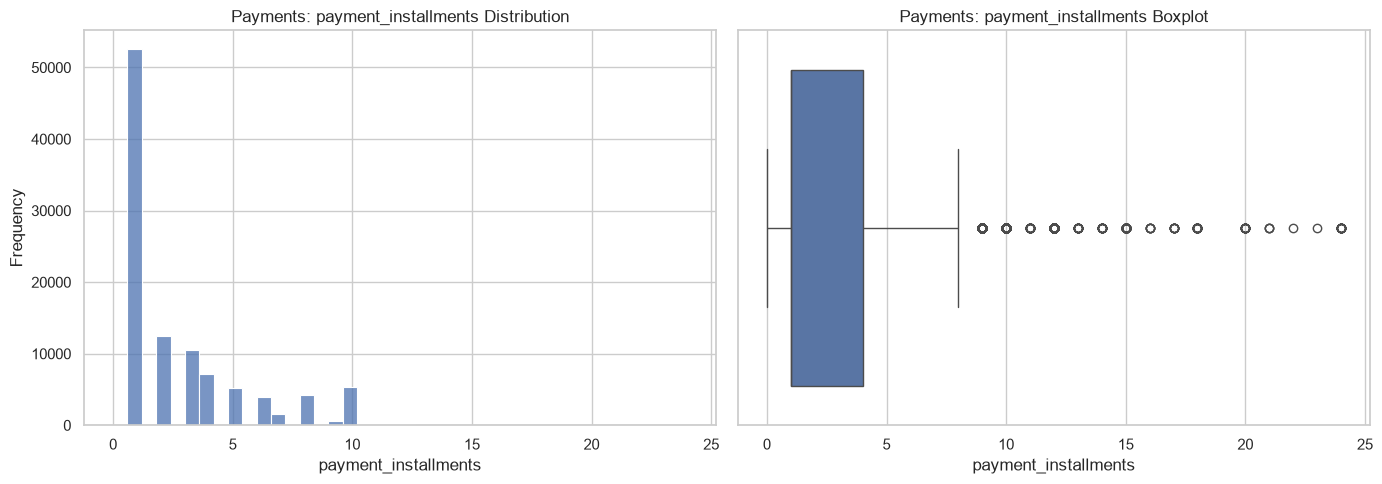

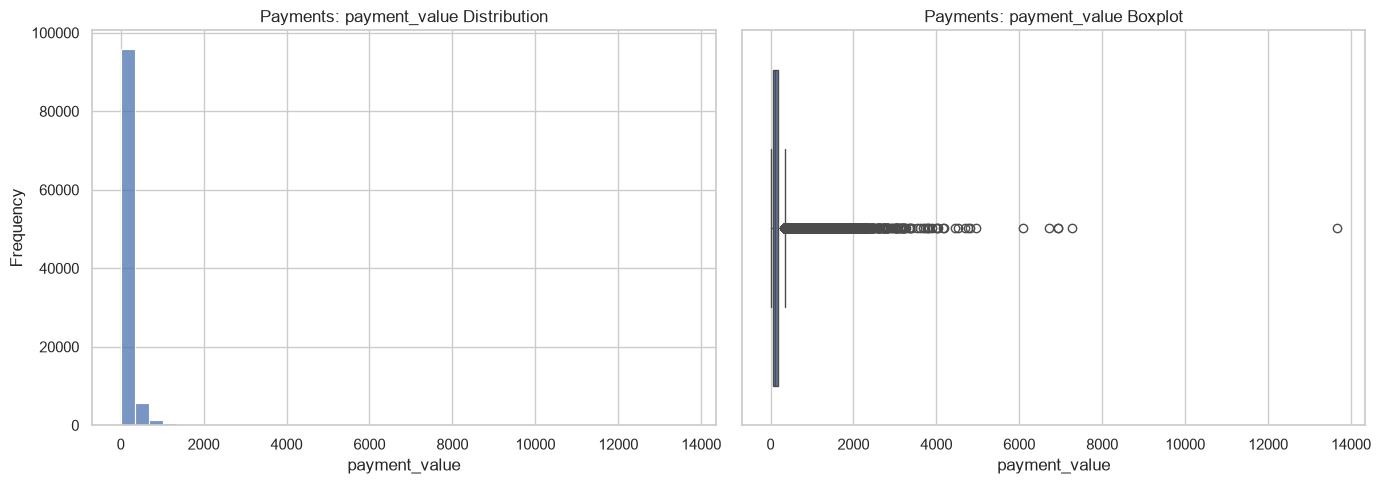

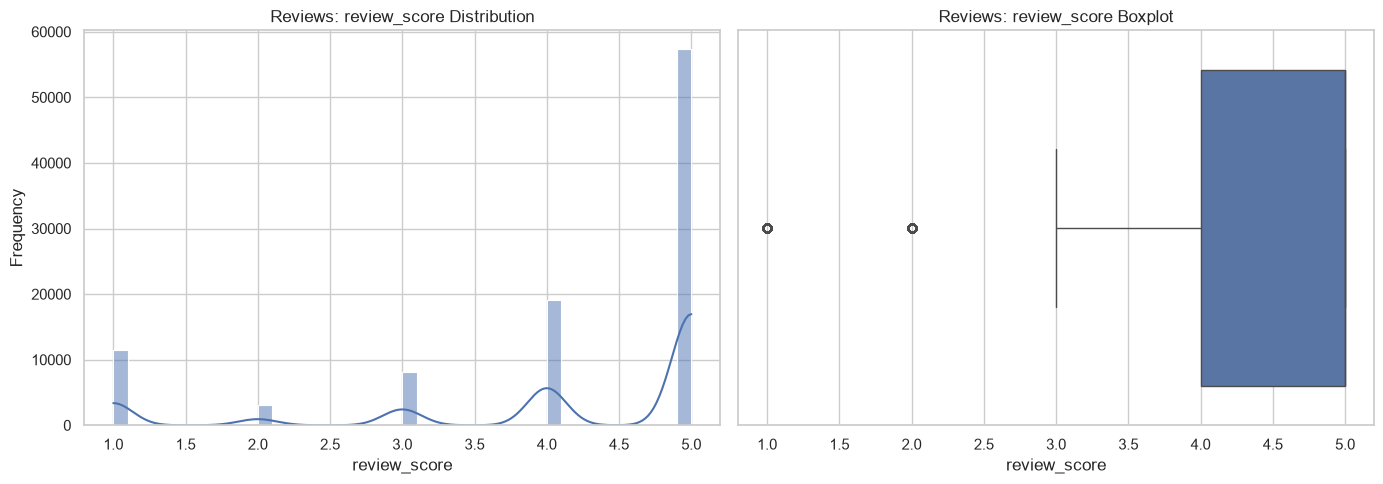

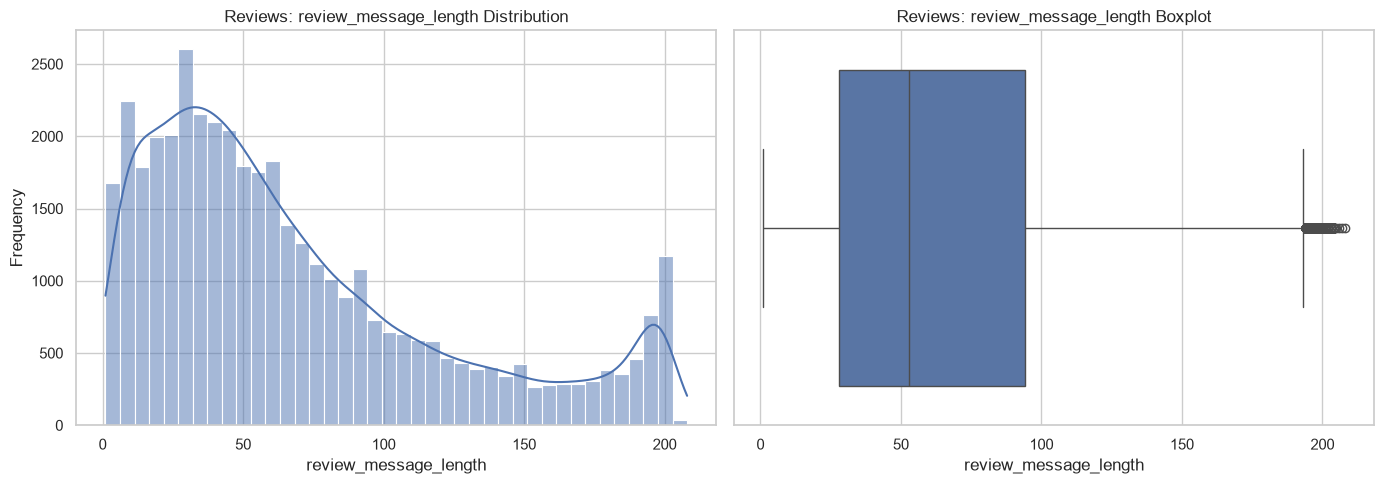

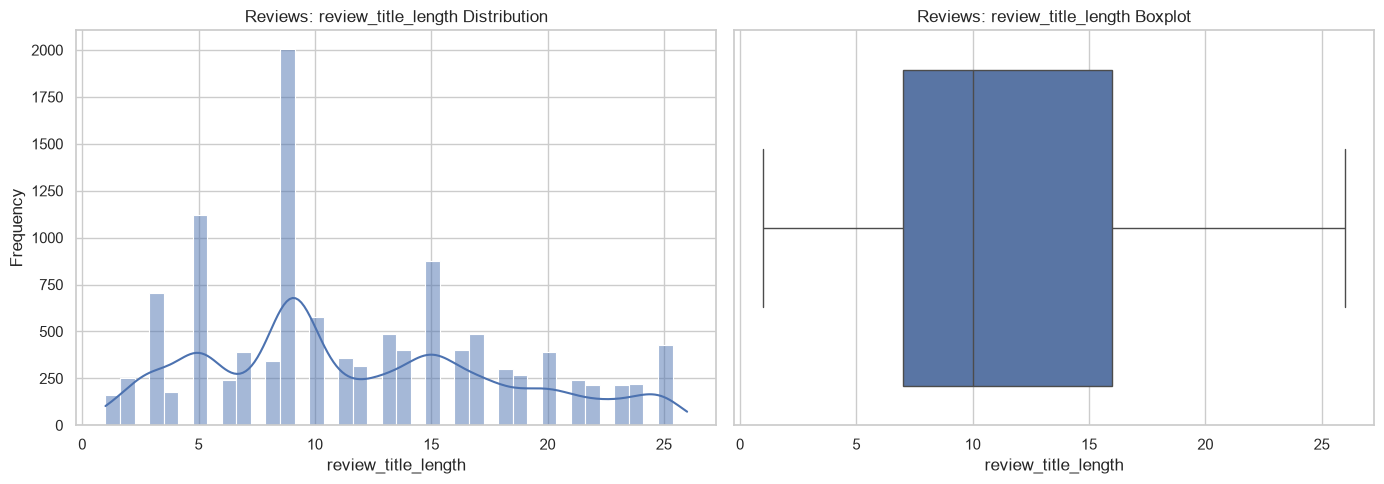

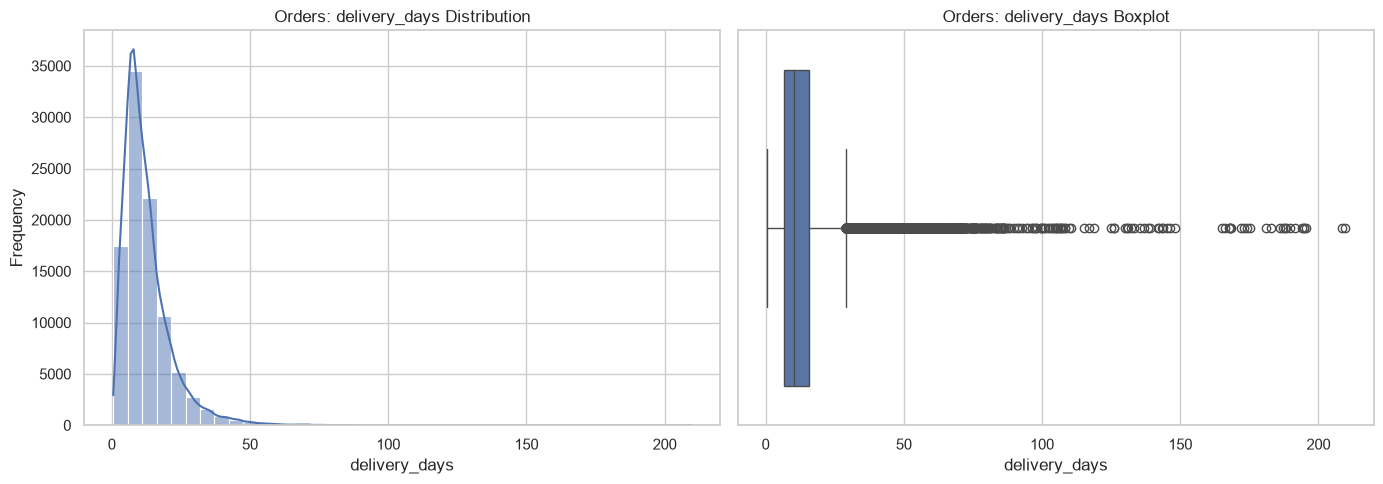

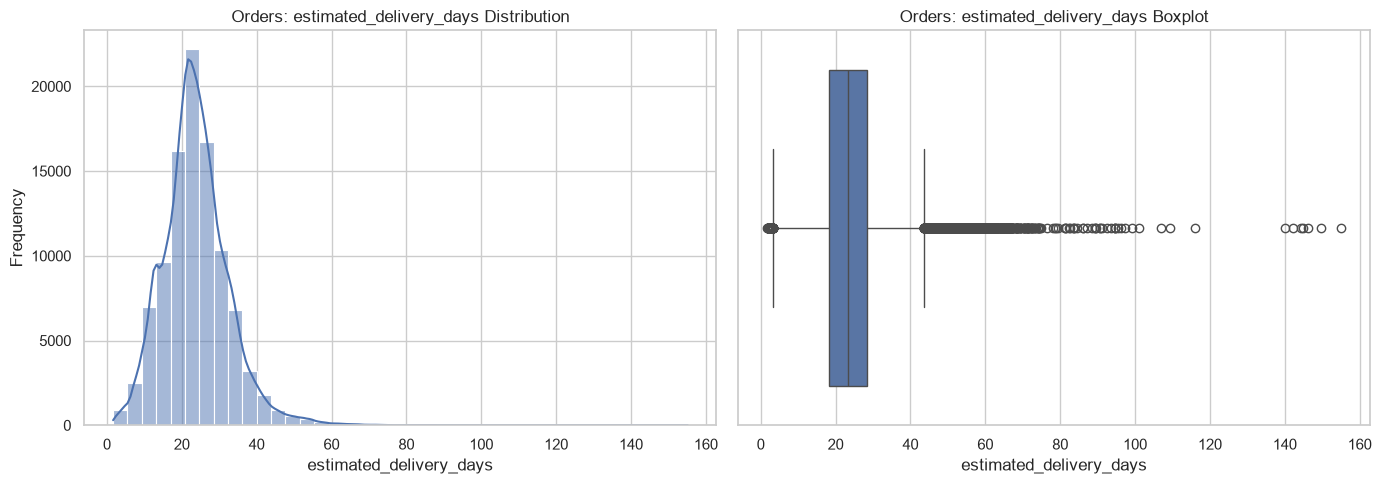

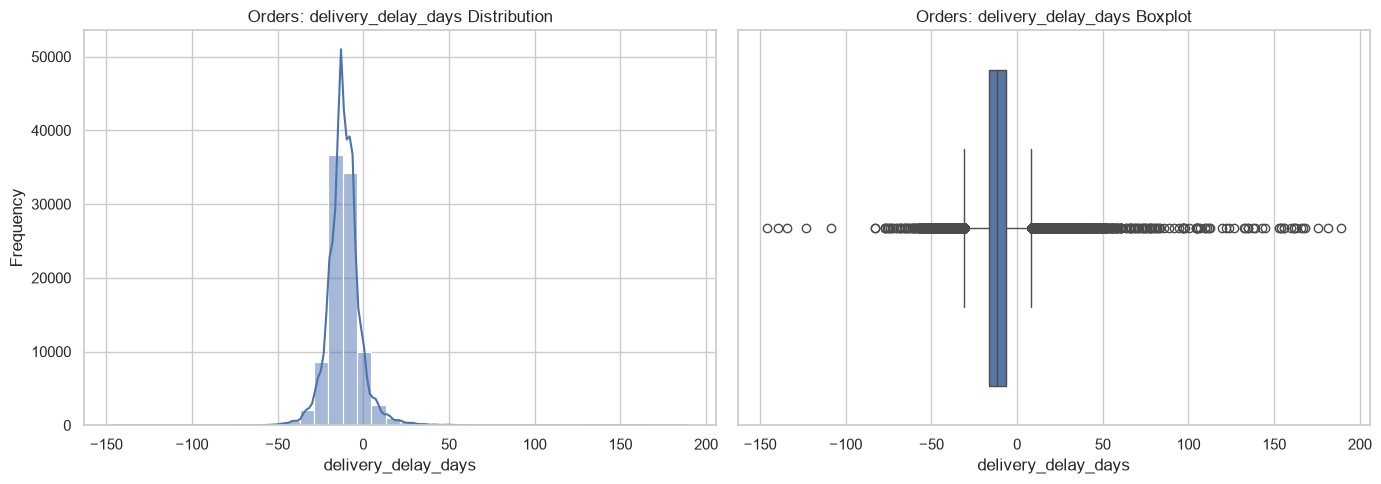

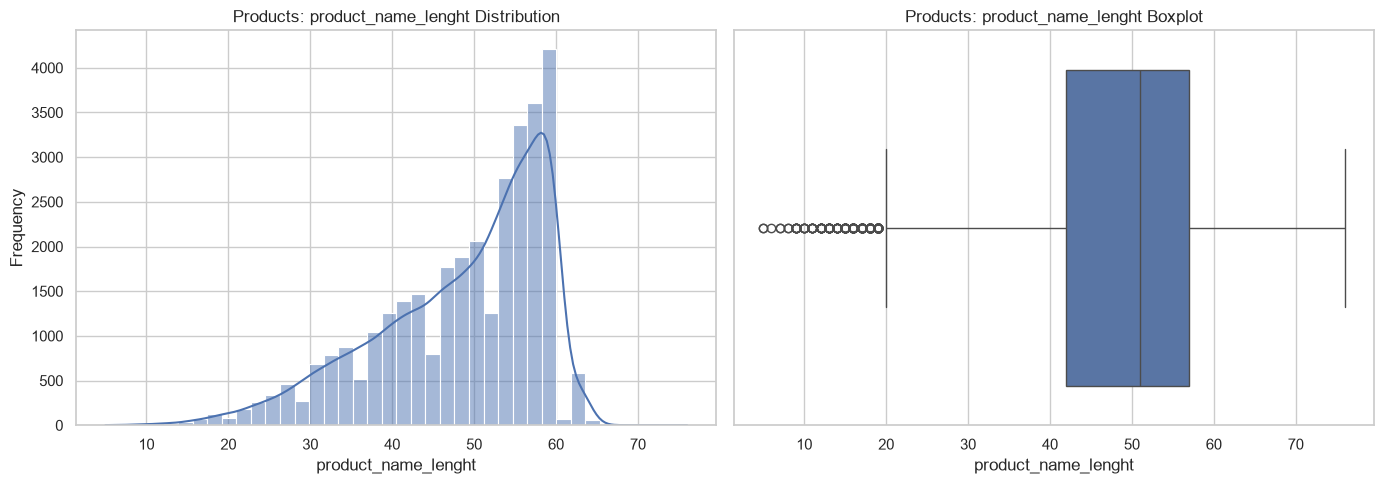

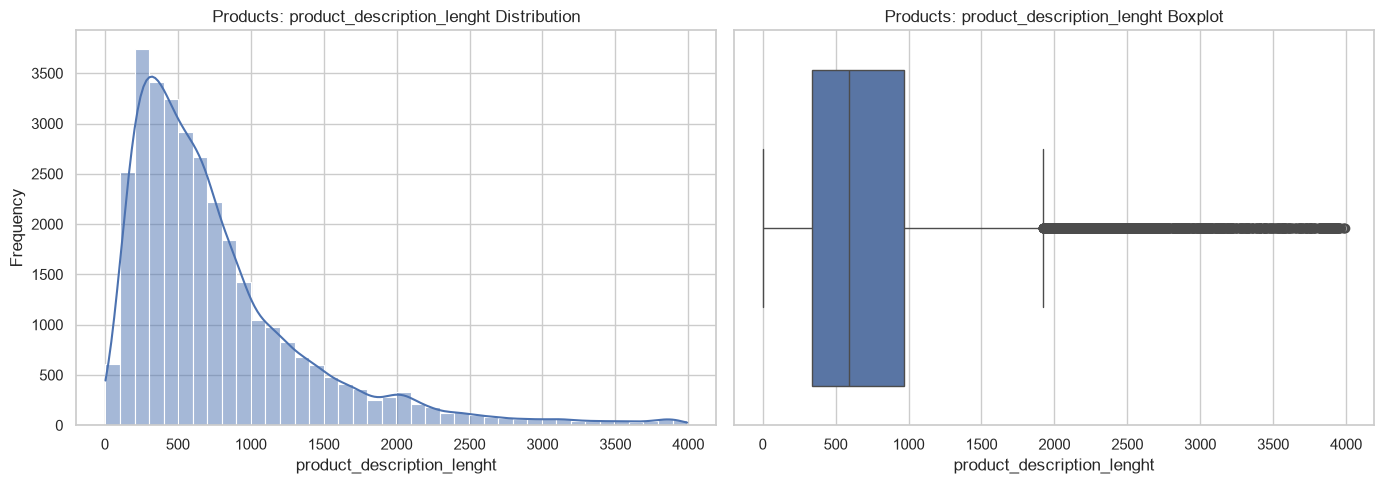

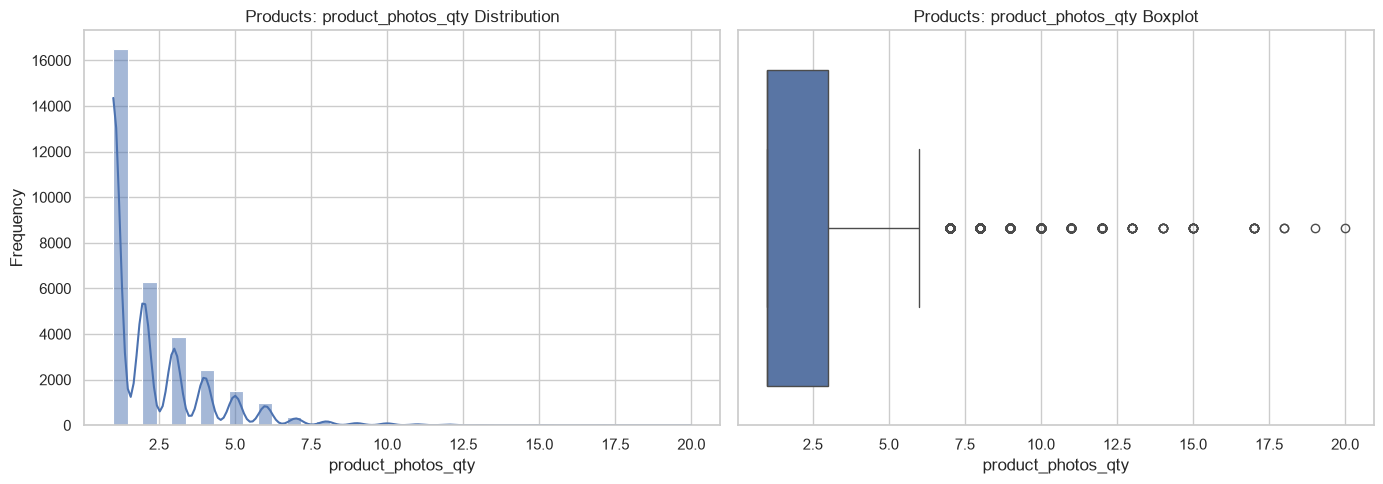

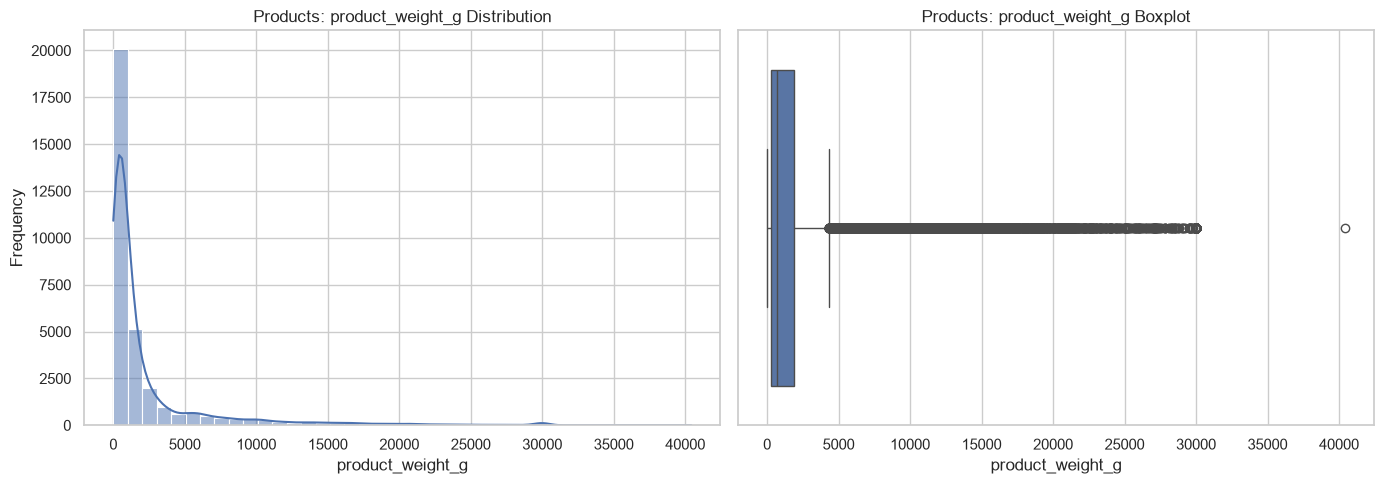

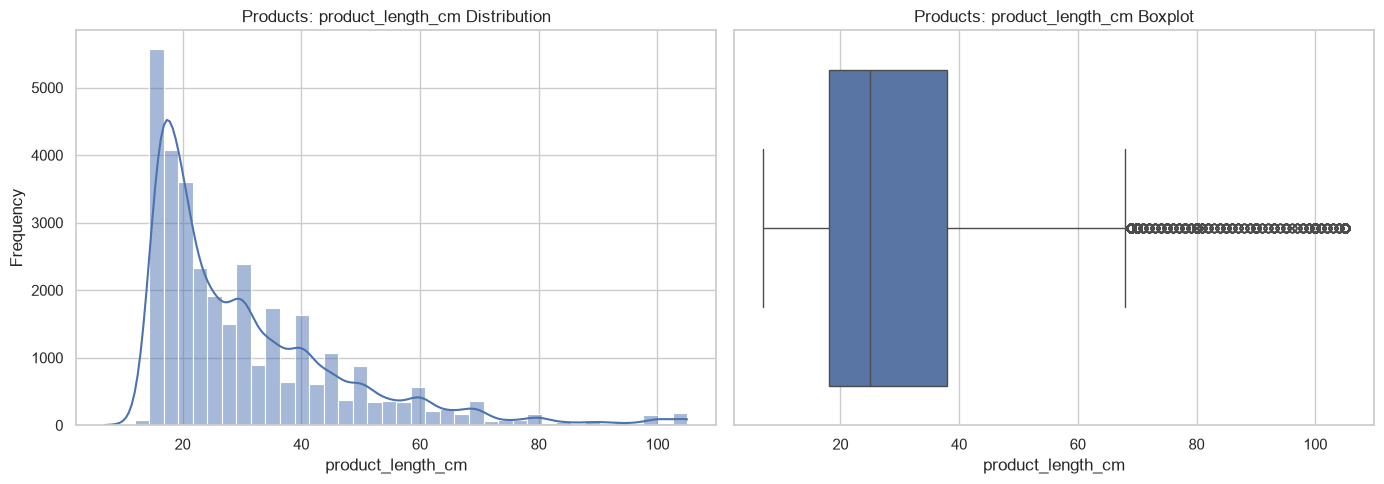

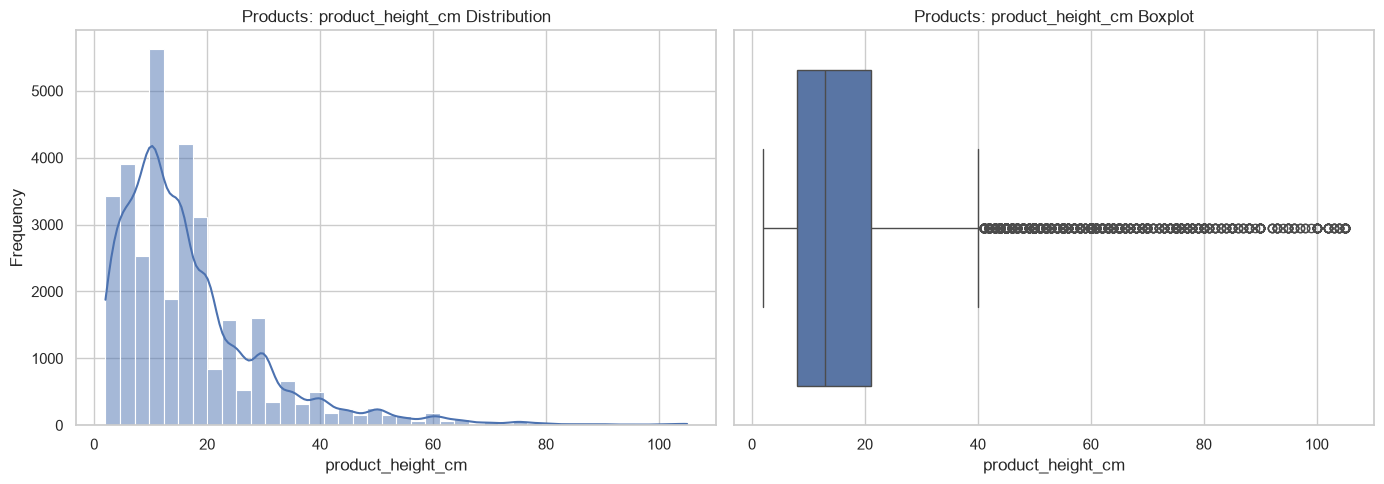

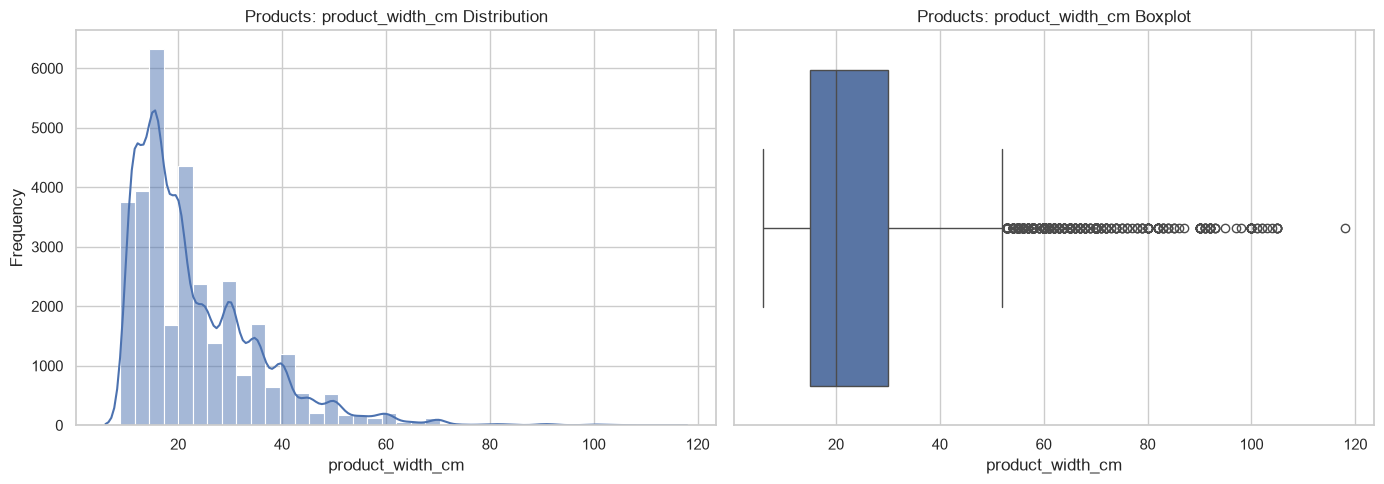

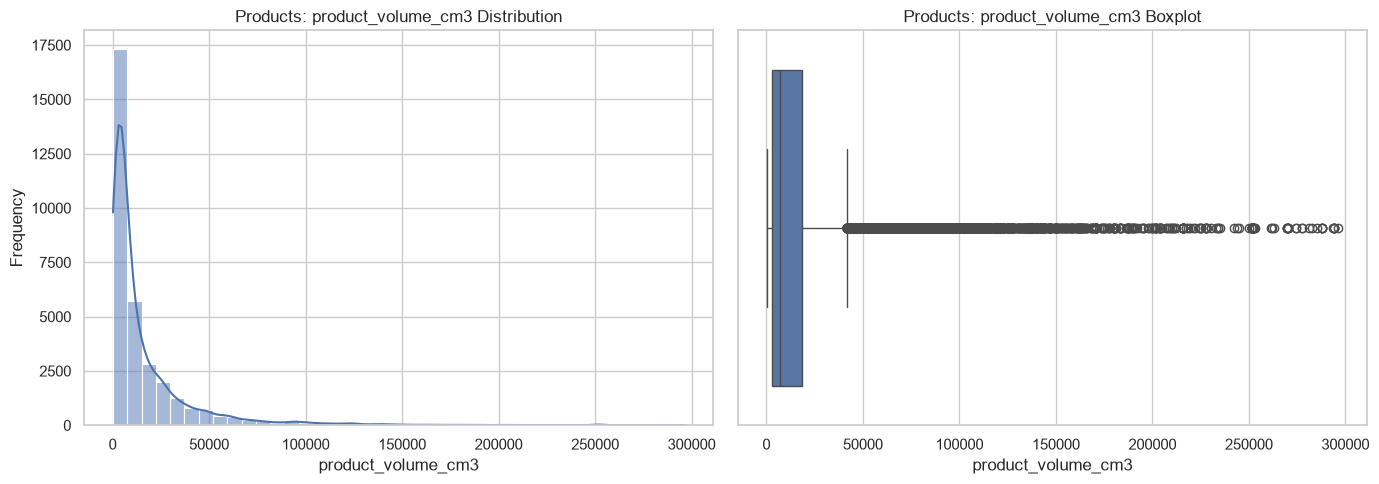

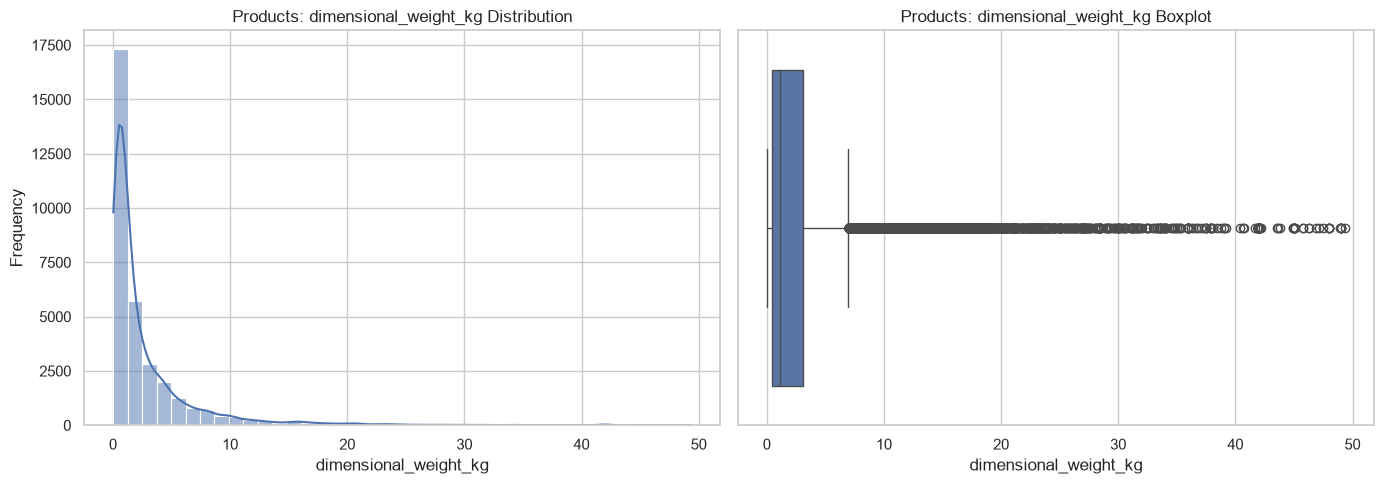

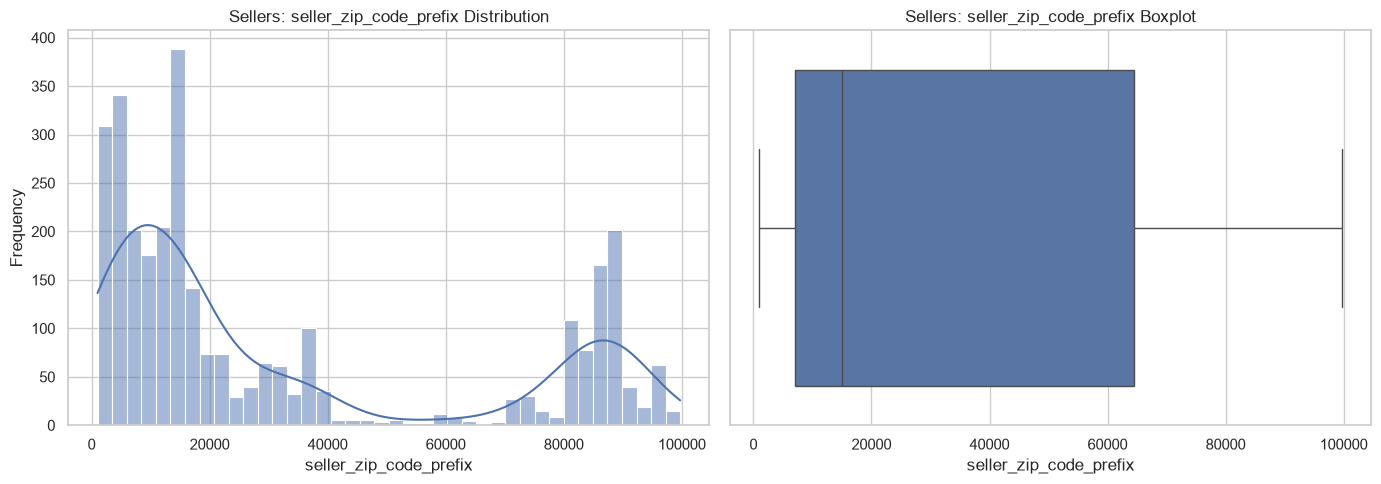


5. CATEGORICAL DISTRIBUTION PLOTS


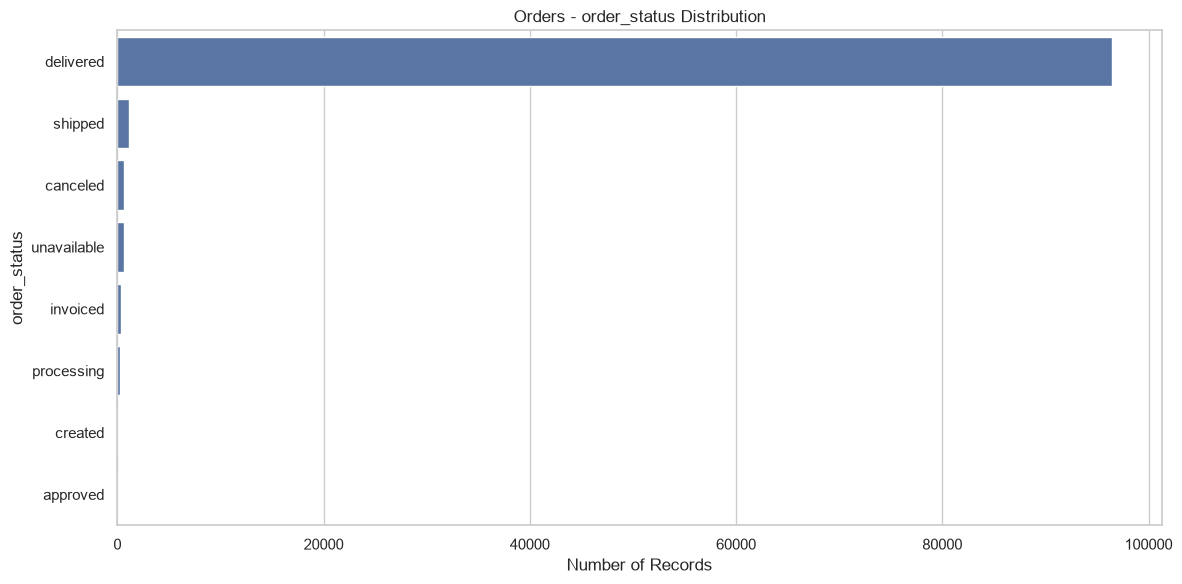

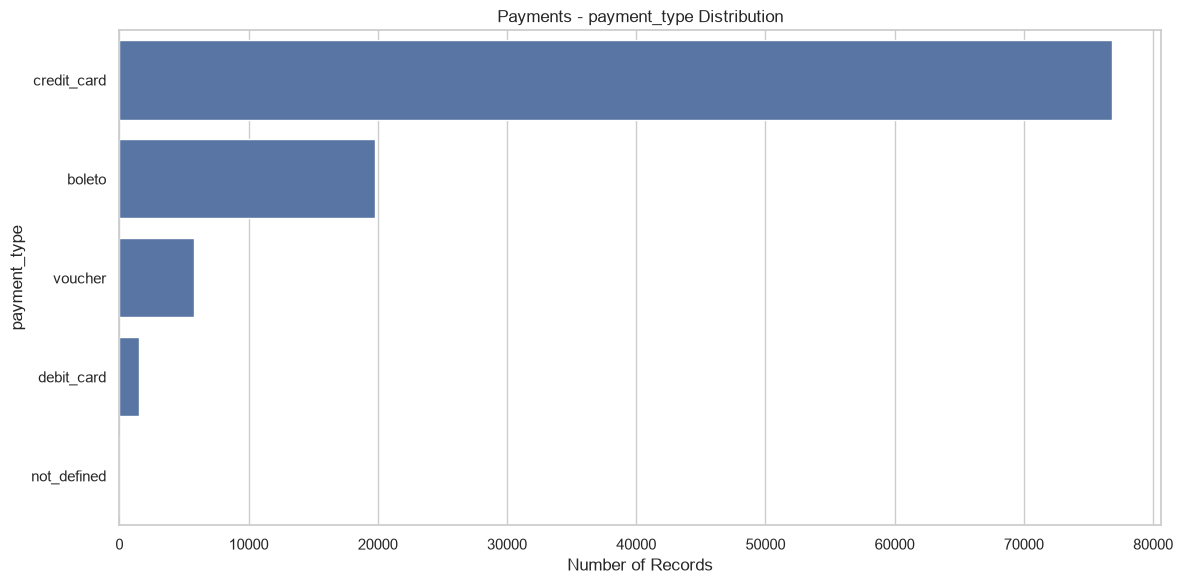

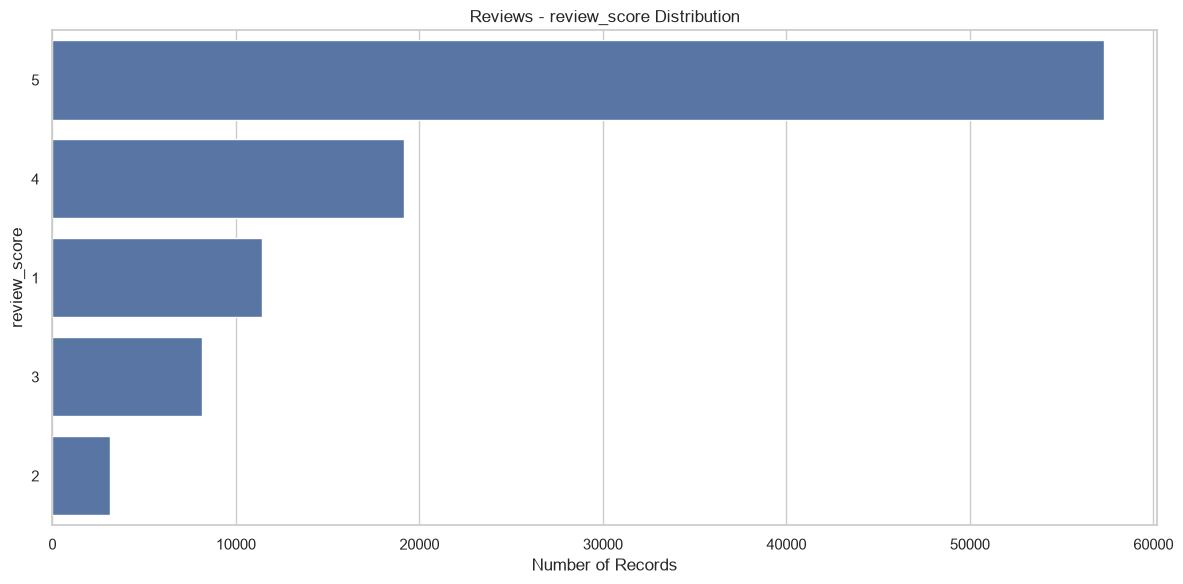

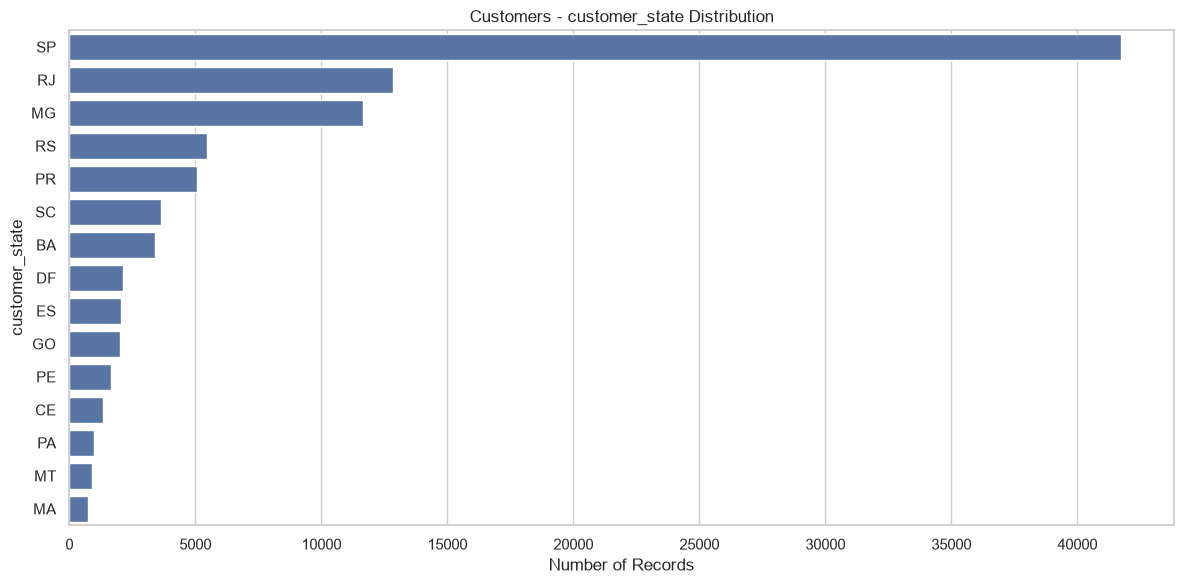

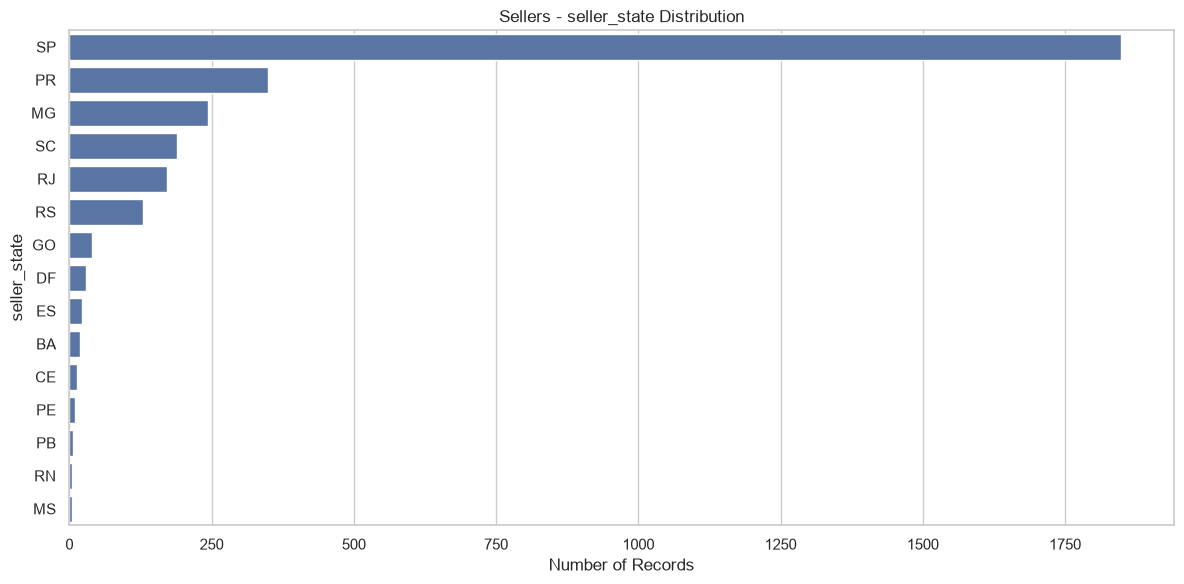

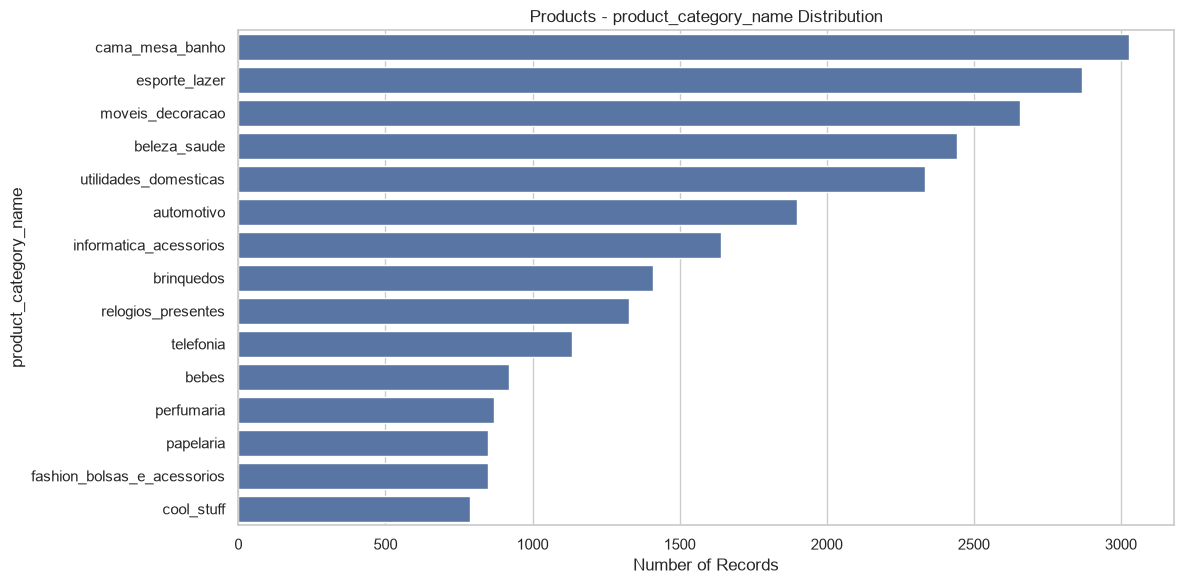

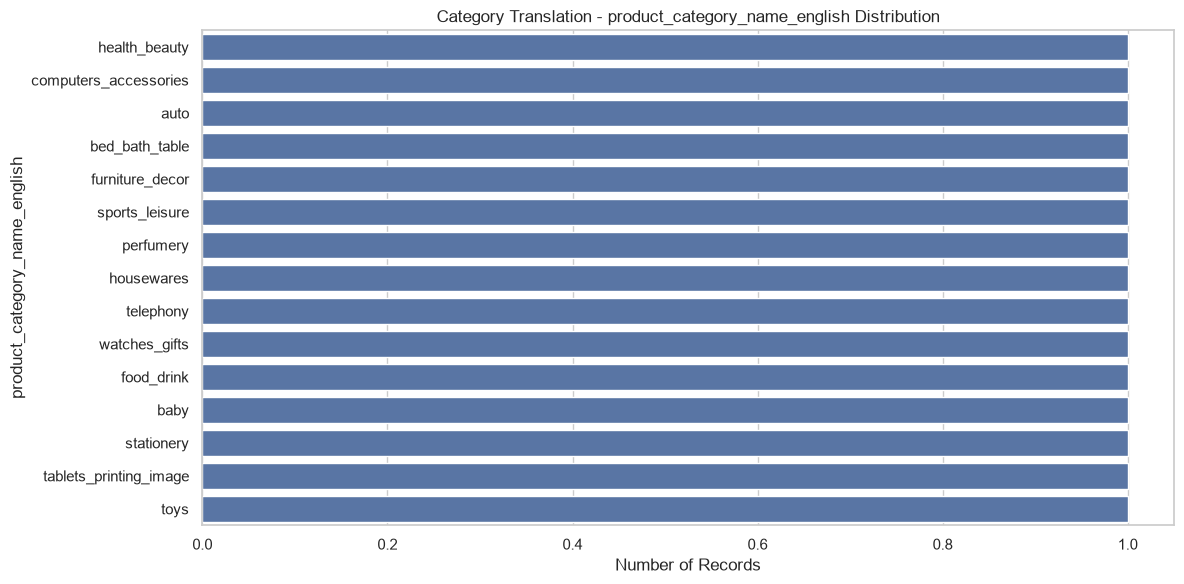


6. MISSING VALUE ANALYSIS


,Dataset,Column,Missing_Count,Missing_Percentage
40,Reviews,review_comment_title,87658,88.34
52,Reviews,review_title_length,87658,88.34
41,Reviews,review_comment_message,58274,58.73
51,Reviews,review_message_length,58274,58.73
60,Orders,order_delivered_customer_date,2965,2.98
70,Orders,delivery_delay_days,2965,2.98
68,Orders,delivery_days,2965,2.98
75,Products,product_name_lenght,610,1.85
74,Products,product_category_name,610,1.85
77,Products,product_photos_qty,610,1.85



7. AUTOMATED UNIVARIATE BUSINESS INSIGHTS

ORDER STATUS
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

PAYMENT METHOD DISTRIBUTION
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

PRODUCT PRICE
Average Price: 120.65 BRL
Median Price: 74.99 BRL

FREIGHT VALUE
Average Freight: 19.99 BRL

CUSTOMER SATISFACTION
Average Review Score: 4.09

TOP 5 CUSTOMER STATES
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64

TOP 5 SELLER STATES
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
Name: count, dtype: int64

UNIVARIATE ANALYSIS COMPLETED SUCCESSFULLY!
Reports and charts saved in: C:\Users\Shashank\Downloads\Projects\DA\E-commerce Sales, Supply Chain & Delivery Intelligenc

In [6]:

# ================================================================
# COMMERCECHAIN 360 - COMPLETE UNIVARIATE ANALYSIS
# E-commerce Sales, Supply Chain & Delivery Intelligence
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. VISUALIZATION CONFIGURATION
# ------------------------------------------------

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------
# 2. PROJECT PATH CONFIGURATION
# ------------------------------------------------

PROJECT_PATH = Path.cwd().parent
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
EDA_PATH = PROJECT_PATH / "reports" / "EDA"

EDA_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 3. LOAD ALL CLEANED DATASETS
# ------------------------------------------------

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv"
)

geolocation = pd.read_csv(
    PROCESSED_PATH / "geolocation_clean.csv"
)

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv",
    parse_dates=["shipping_limit_date"]
)

payments = pd.read_csv(
    PROCESSED_PATH / "payments_clean.csv"
)

reviews = pd.read_csv(
    PROCESSED_PATH / "reviews_clean.csv",
    parse_dates=[
        "review_creation_date",
        "review_answer_timestamp"
    ]
)

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv"
)

sellers = pd.read_csv(
    PROCESSED_PATH / "sellers_clean.csv"
)

category_translation = pd.read_csv(
    PROCESSED_PATH / "category_translation_clean.csv"
)

datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

print("=" * 65)
print("COMMERCECHAIN 360 - UNIVARIATE ANALYSIS")
print("=" * 65)

# ------------------------------------------------
# 4. DATASET OVERVIEW
# ------------------------------------------------

overview = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 2
        )
    }
    for name, df in datasets.items()
])

print("\n1. DATASET OVERVIEW")
display(overview)

# ------------------------------------------------
# 5. NUMERICAL DESCRIPTIVE STATISTICS
# ------------------------------------------------

print("\n2. NUMERICAL DESCRIPTIVE STATISTICS")

numerical_reports = {}

for name, df in datasets.items():

    numeric_df = df.select_dtypes(include=np.number)

    if not numeric_df.empty:

        stats = numeric_df.describe().T

        stats["missing"] = numeric_df.isnull().sum()

        stats["skewness"] = numeric_df.skew()

        stats["kurtosis"] = numeric_df.kurtosis()

        numerical_reports[name] = stats

        print(f"\n{name} - Numerical Statistics")
        display(stats.round(2))

# ------------------------------------------------
# 6. CATEGORICAL FREQUENCY ANALYSIS
# ------------------------------------------------

print("\n3. CATEGORICAL FREQUENCY ANALYSIS")

categorical_reports = {}

for name, df in datasets.items():

    categorical_columns = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in categorical_columns:

        # Avoid printing high-cardinality identifier columns
        if df[col].nunique(dropna=True) > 100:
            continue

        frequency = (
            df[col]
            .value_counts(dropna=False)
            .head(15)
            .reset_index()
        )

        frequency.columns = ["Category", "Count"]

        categorical_reports[f"{name}_{col}"] = frequency

        print(f"\n{name} - {col}")
        display(frequency)

# ------------------------------------------------
# 7. NUMERICAL DISTRIBUTION VISUALIZATIONS
# ------------------------------------------------

print("\n4. NUMERICAL DISTRIBUTION PLOTS")

for name, df in datasets.items():

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    # Exclude artificial flags and identifier-like integer fields
    numeric_columns = [
        col for col in numeric_columns
        if not (
            col.startswith("invalid_") or
            col.startswith("duplicate_") or
            col in ["order_item_id", "payment_sequential"]
        )
    ]

    if not numeric_columns:
        continue

    for col in numeric_columns:

        values = df[col].dropna()

        if values.empty or values.nunique() <= 1:
            continue

        # Plot extreme-skewed variables on a raw scale for inspection
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        sns.histplot(
            values,
            bins=40,
            kde=(len(values) <= 100000),
            ax=axes[0]
        )

        axes[0].set_title(f"{name}: {col} Distribution")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")

        sns.boxplot(
            x=values,
            ax=axes[1]
        )

        axes[1].set_title(f"{name}: {col} Boxplot")
        axes[1].set_xlabel(col)

        plt.tight_layout()

        safe_name = (
            f"{name}_{col}".lower().replace(" ", "_")
        )

        plt.savefig(
            EDA_PATH / f"univariate_{safe_name}.png",
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# ------------------------------------------------
# 8. CATEGORICAL DISTRIBUTION VISUALIZATIONS
# ------------------------------------------------

print("\n5. CATEGORICAL DISTRIBUTION PLOTS")

selected_categorical_columns = {
    "Orders": ["order_status"],
    "Payments": ["payment_type"],
    "Reviews": ["review_score"],
    "Customers": ["customer_state"],
    "Sellers": ["seller_state"],
    "Products": ["product_category_name"],
    "Category Translation": [
        "product_category_name_english"
    ]
}

for dataset_name, columns in selected_categorical_columns.items():

    df = datasets[dataset_name]

    for col in columns:

        if col not in df.columns:
            continue

        counts = df[col].value_counts().head(15)

        plt.figure(figsize=(12, 6))

        sns.barplot(
            x=counts.values,
            y=counts.index.astype(str)
        )

        plt.title(
            f"{dataset_name} - {col} Distribution"
        )

        plt.xlabel("Number of Records")
        plt.ylabel(col)

        plt.tight_layout()

        plt.savefig(
            EDA_PATH /
            f"categorical_{dataset_name.lower()}_{col}.png",
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# ------------------------------------------------
# 9. MISSING VALUE ANALYSIS
# ------------------------------------------------

print("\n6. MISSING VALUE ANALYSIS")

missing_report = []

for name, df in datasets.items():

    for col in df.columns:

        missing_count = df[col].isnull().sum()

        missing_report.append({
            "Dataset": name,
            "Column": col,
            "Missing_Count": missing_count,
            "Missing_Percentage": round(
                missing_count / len(df) * 100, 2
            )
        })

missing_df = pd.DataFrame(missing_report)

missing_df = missing_df.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(
    missing_df[missing_df["Missing_Count"] > 0]
)

# ------------------------------------------------
# 10. AUTOMATED BUSINESS INSIGHTS
# ------------------------------------------------

print("\n7. AUTOMATED UNIVARIATE BUSINESS INSIGHTS")

# Order status
print("\nORDER STATUS")

print(orders["order_status"].value_counts())

# Payment methods
print("\nPAYMENT METHOD DISTRIBUTION")

print(payments["payment_type"].value_counts())

# Average product price
print("\nPRODUCT PRICE")

print(
    "Average Price:",
    round(order_items["price"].mean(), 2),
    "BRL"
)

print(
    "Median Price:",
    round(order_items["price"].median(), 2),
    "BRL"
)

# Average freight
print("\nFREIGHT VALUE")

print(
    "Average Freight:",
    round(order_items["freight_value"].mean(), 2),
    "BRL"
)

# Customer review
print("\nCUSTOMER SATISFACTION")

print(
    "Average Review Score:",
    round(reviews["review_score"].mean(), 2)
)

# Customer states
print("\nTOP 5 CUSTOMER STATES")

print(
    customers["customer_state"]
    .value_counts()
    .head(5)
)

# Seller states
print("\nTOP 5 SELLER STATES")

print(
    sellers["seller_state"]
    .value_counts()
    .head(5)
)

# ------------------------------------------------
# 11. EXPORT ANALYSIS REPORTS
# ------------------------------------------------

overview.to_csv(
    EDA_PATH / "univariate_dataset_overview.csv",
    index=False
)

missing_df.to_csv(
    EDA_PATH / "univariate_missing_values.csv",
    index=False
)

# Combine numerical statistics
if numerical_reports:

    combined_numeric = pd.concat(
        numerical_reports,
        names=["Dataset", "Column"]
    )

    combined_numeric.to_excel(
        EDA_PATH / "univariate_numerical_statistics.xlsx"
    )

# Export categorical reports
if categorical_reports:

    with pd.ExcelWriter(
        EDA_PATH / "univariate_categorical_statistics.xlsx"
    ) as writer:

        for sheet_name, report in categorical_reports.items():

            safe_sheet = sheet_name[:31]

            report.to_excel(
                writer,
                sheet_name=safe_sheet,
                index=False
            )

print("\n" + "=" * 65)
print("UNIVARIATE ANALYSIS COMPLETED SUCCESSFULLY!")
print("Reports and charts saved in:", EDA_PATH)
print("=" * 65)


All datasets loaded successfully!

1. PRICE VS FREIGHT ANALYSIS
Price-Freight Correlation: 0.414


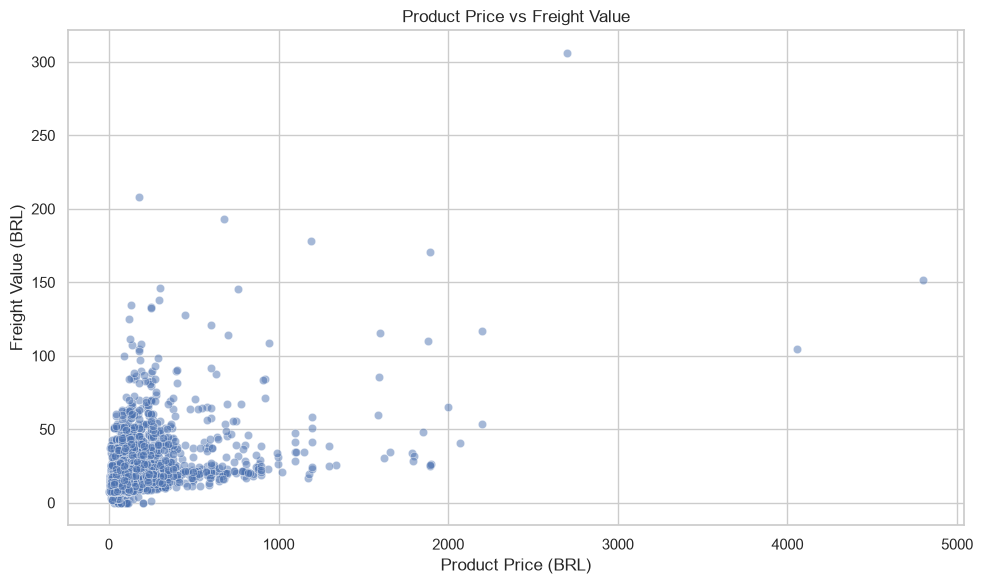


2. CATEGORY VS REVENUE


,Total_Revenue,Total_Items,Average_Price
product_category_name_english,,,
health_beauty,1258681.34,9670,130.16
watches_gifts,1205005.68,5991,201.14
bed_bath_table,1036988.68,11115,93.30
sports_leisure,988048.97,8641,114.34
computers_accessories,911954.32,7827,116.51
furniture_decor,729762.49,8334,87.56
cool_stuff,635290.85,3796,167.36
housewares,632248.66,6964,90.79
auto,592720.11,4235,139.96


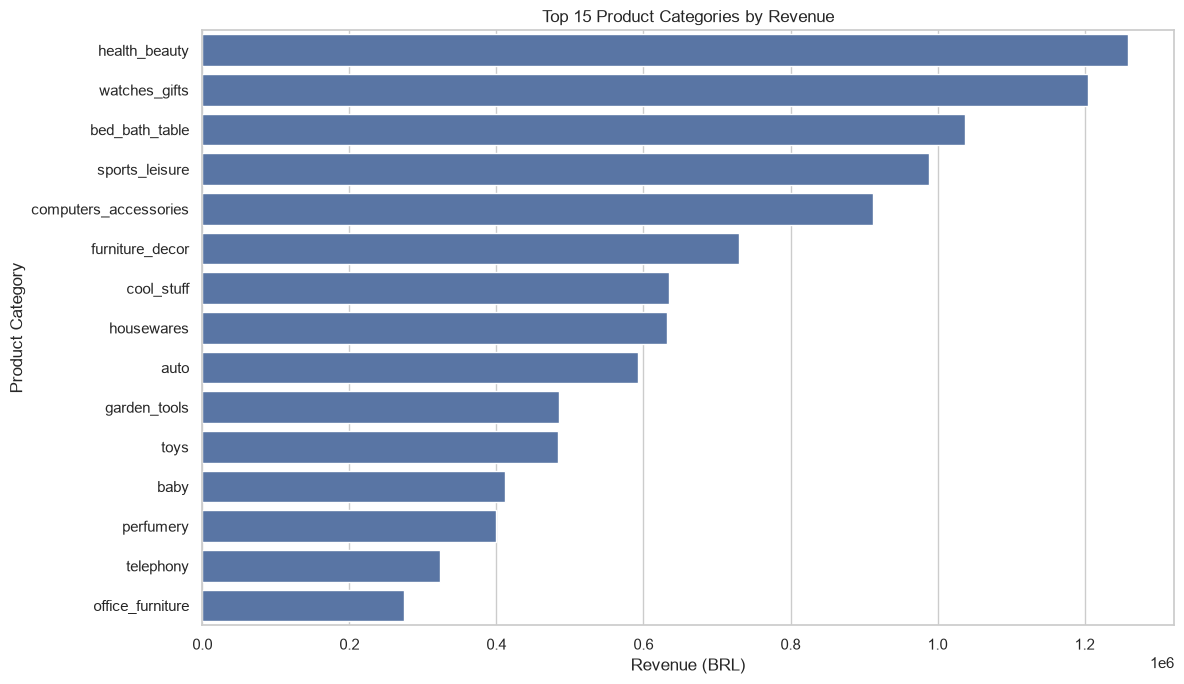


3. PAYMENT TYPE VS PAYMENT VALUE


,Total_Payment,Average_Payment,Transactions
payment_type,,,
credit_card,12542084.19,163.32,76795
boleto,2869361.27,145.03,19784
voucher,379436.87,65.70,5775
debit_card,217989.79,142.57,1529
not_defined,0.00,0.00,3


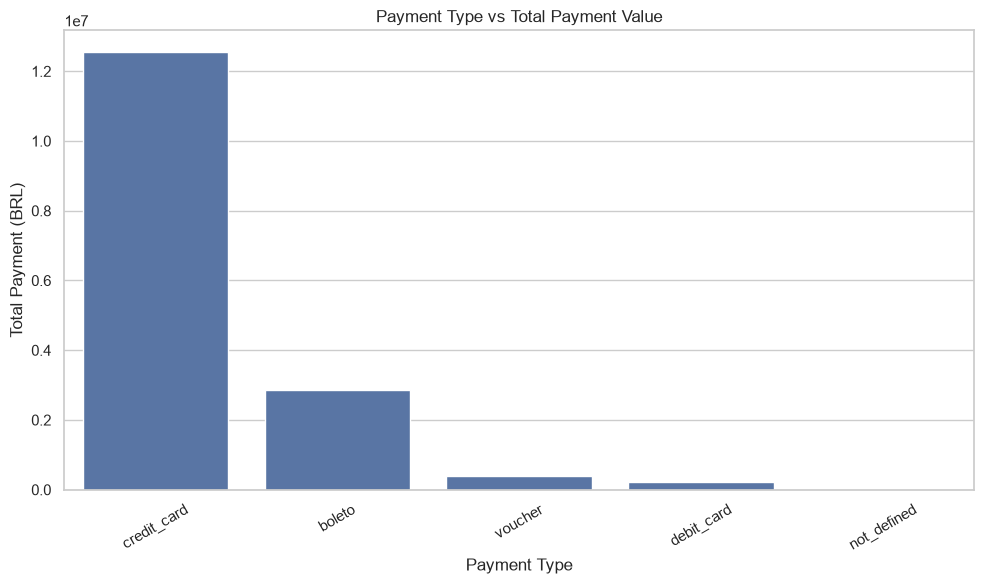


4. DELIVERY PERFORMANCE VS REVIEW SCORE


,Average_Review_Score,Total_Reviews
delivery_status,,
Late,2.57,7700
Not Delivered / Unknown,1.76,2871
On Time / Early,4.29,88653


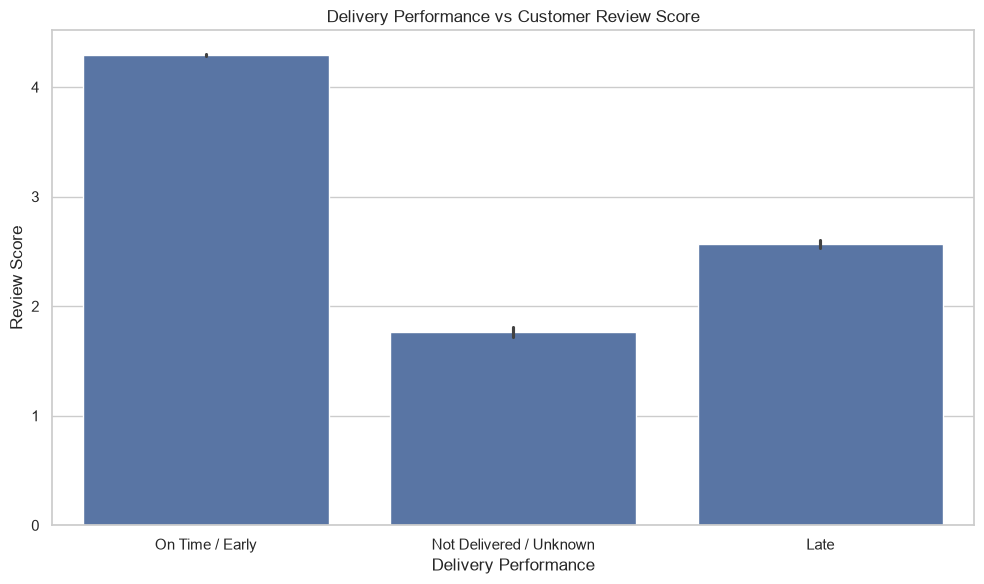


5. CUSTOMER STATE VS ORDER VOLUME


,Total_Orders
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


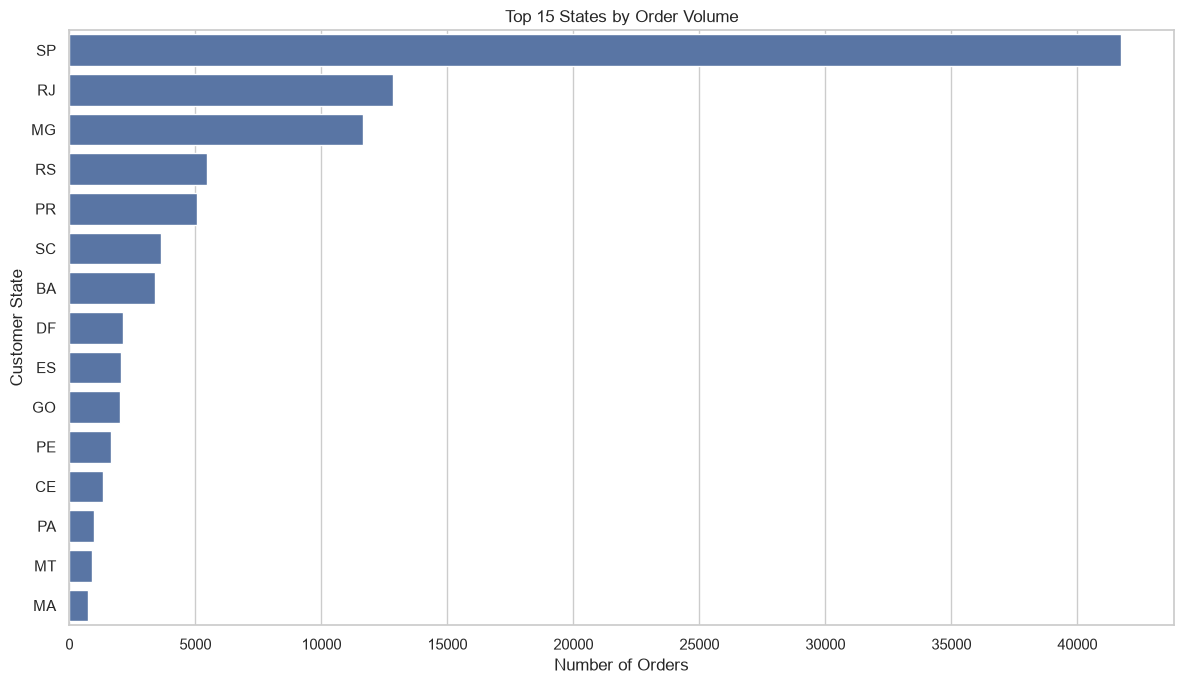


6. PRODUCT CATEGORY VS REVIEW SCORE


,Average_Review,Review_Count
product_category_name_english,,
books_general_interest,4.45,549
costruction_tools_tools,4.44,99
flowers,4.42,31
books_imported,4.40,60
books_technical,4.37,266
food_drink,4.32,279
luggage_accessories,4.32,1088
small_appliances_home_oven_and_coffee,4.30,76
fashion_sport,4.26,31


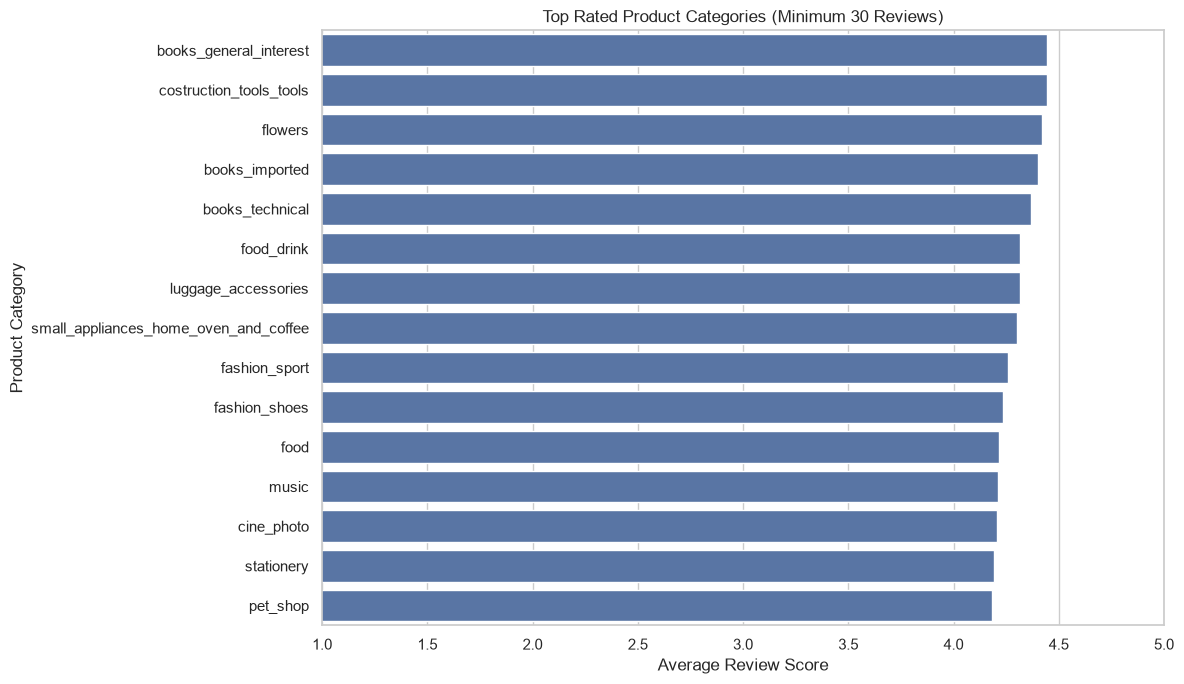


7. SELLER STATE VS SALES REVENUE


,Total_Revenue,Total_Items,Unique_Sellers
seller_state,,,
SP,8753396.21,80342,1849
PR,1261887.21,8671,349
MG,1011564.74,8827,244
RJ,843984.22,4818,171
SC,632426.07,4075,190
RS,378559.54,2199,129
BA,285561.56,643,19
DF,97749.48,899,30
PE,91493.85,448,9


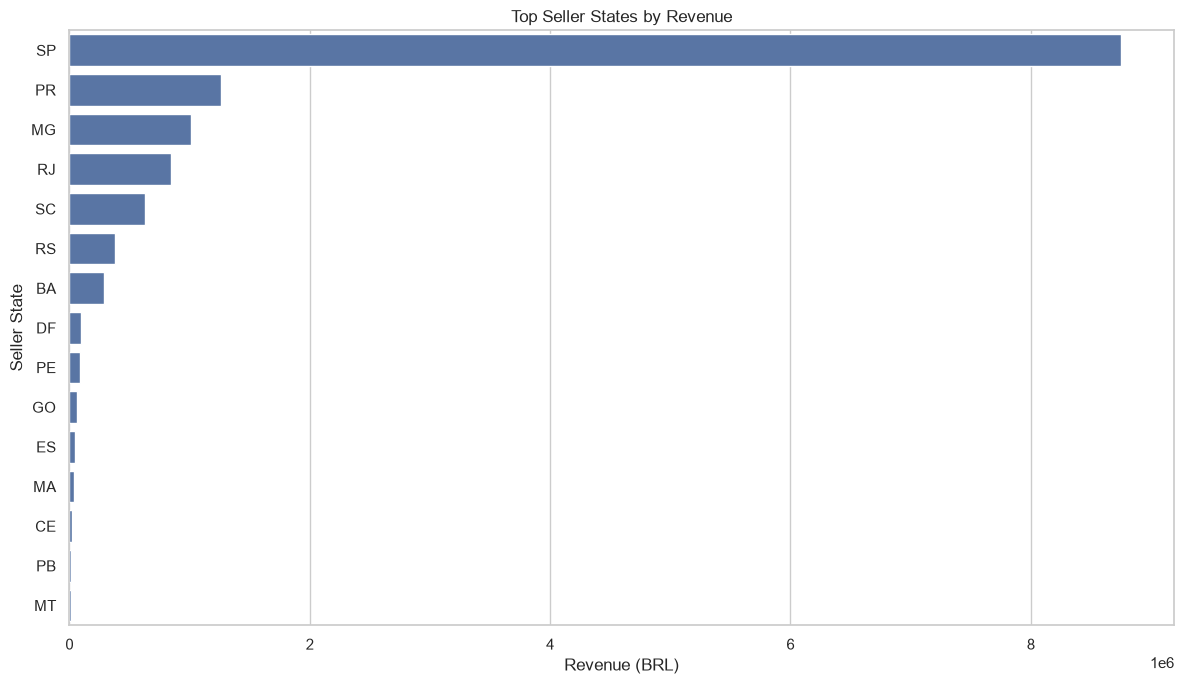


BIVARIATE ANALYSIS COMPLETED SUCCESSFULLY!
Reports and charts saved in: C:\Users\Shashank\Downloads\Projects\DA\E-commerce Sales, Supply Chain & Delivery Intelligence Platform\reports\EDA


In [7]:

# ============================================================
# COMMERCECHAIN 360 - BIVARIATE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_PATH = Path.cwd().parent
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
EDA_PATH = PROJECT_PATH / "reports" / "EDA"

EDA_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------------------

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    dtype={"order_id": "string", "customer_id": "string"},
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv",
    dtype={
        "order_id": "string",
        "product_id": "string",
        "seller_id": "string"
    },
    parse_dates=["shipping_limit_date"]
)

payments = pd.read_csv(
    PROCESSED_PATH / "payments_clean.csv",
    dtype={"order_id": "string"}
)

reviews = pd.read_csv(
    PROCESSED_PATH / "reviews_clean.csv",
    dtype={"order_id": "string"}
)

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv",
    dtype={"product_id": "string"}
)

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv",
    dtype={"customer_id": "string"}
)

sellers = pd.read_csv(
    PROCESSED_PATH / "sellers_clean.csv",
    dtype={"seller_id": "string"}
)

category_translation = pd.read_csv(
    PROCESSED_PATH / "category_translation_clean.csv"
)

print("All datasets loaded successfully!")

# ------------------------------------------------------------
# 3. PREPARE ANALYTICAL DATASETS
# ------------------------------------------------------------

# Product category translation
products_analysis = products.merge(
    category_translation[
        ["product_category_name",
         "product_category_name_english"]
    ],
    on="product_category_name",
    how="left"
)

# Order item analysis with products and sellers
sales_analysis = (
    order_items
    .merge(
        products_analysis[
            ["product_id", "product_category_name_english"]
        ],
        on="product_id",
        how="left"
    )
    .merge(
        sellers[["seller_id", "seller_state"]],
        on="seller_id",
        how="left"
    )
)

# Delivery analysis
delivery_analysis = orders[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days"
    ]
].copy()

# Add delivery category
delivery_analysis["delivery_status"] = np.select(
    [
        delivery_analysis["order_status"].eq("delivered") &
        delivery_analysis["delivery_delay_days"].notna() &
        (delivery_analysis["delivery_delay_days"] > 0),

        delivery_analysis["order_status"].eq("delivered") &
        delivery_analysis["delivery_delay_days"].notna() &
        (delivery_analysis["delivery_delay_days"] <= 0)
    ],
    ["Late", "On Time / Early"],
    default="Not Delivered / Unknown"
)

# ------------------------------------------------------------
# 4. PRICE VS FREIGHT ANALYSIS
# ------------------------------------------------------------

print("\n1. PRICE VS FREIGHT ANALYSIS")

price_freight = order_items[
    ["price", "freight_value"]
].dropna()

correlation = price_freight["price"].corr(
    price_freight["freight_value"]
)

print("Price-Freight Correlation:", round(correlation, 3))

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=price_freight.sample(
        min(5000, len(price_freight)),
        random_state=42
    ),
    x="price",
    y="freight_value",
    alpha=0.5
)

plt.title("Product Price vs Freight Value")
plt.xlabel("Product Price (BRL)")
plt.ylabel("Freight Value (BRL)")
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_price_vs_freight.png")
plt.show()

# ------------------------------------------------------------
# 5. PRODUCT CATEGORY VS REVENUE
# ------------------------------------------------------------

print("\n2. CATEGORY VS REVENUE")

category_revenue = (
    sales_analysis
    .dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")
    .agg(
        Total_Revenue=("price", "sum"),
        Total_Items=("order_item_id", "count"),
        Average_Price=("price", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(15)
)

display(category_revenue.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_revenue.reset_index(),
    x="Total_Revenue",
    y="product_category_name_english"
)

plt.title("Top 15 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_category_revenue.png")
plt.show()

# ------------------------------------------------------------
# 6. PAYMENT TYPE VS PAYMENT VALUE
# ------------------------------------------------------------

print("\n3. PAYMENT TYPE VS PAYMENT VALUE")

payment_analysis = (
    payments
    .groupby("payment_type")
    .agg(
        Total_Payment=("payment_value", "sum"),
        Average_Payment=("payment_value", "mean"),
        Transactions=("payment_value", "count")
    )
    .sort_values("Total_Payment", ascending=False)
)

display(payment_analysis.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=payment_analysis.reset_index(),
    x="payment_type",
    y="Total_Payment"
)

plt.title("Payment Type vs Total Payment Value")
plt.xlabel("Payment Type")
plt.ylabel("Total Payment (BRL)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_payment_analysis.png")
plt.show()

# ------------------------------------------------------------
# 7. DELIVERY PERFORMANCE VS REVIEW SCORE
# ------------------------------------------------------------

print("\n4. DELIVERY PERFORMANCE VS REVIEW SCORE")

delivery_review = delivery_analysis[
    ["order_id", "delivery_status"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

delivery_review_summary = (
    delivery_review
    .groupby("delivery_status")
    .agg(
        Average_Review_Score=("review_score", "mean"),
        Total_Reviews=("review_score", "count")
    )
)

display(delivery_review_summary.round(2))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=delivery_review.reset_index(),
    x="delivery_status",
    y="review_score"
)

plt.title("Delivery Performance vs Customer Review Score")
plt.xlabel("Delivery Performance")
plt.ylabel("Review Score")
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_delivery_vs_reviews.png")
plt.show()

# ------------------------------------------------------------
# 8. CUSTOMER STATE VS ORDER VOLUME
# ------------------------------------------------------------

print("\n5. CUSTOMER STATE VS ORDER VOLUME")

customer_orders = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

state_orders = (
    customer_orders
    .groupby("customer_state")
    .agg(Total_Orders=("order_id", "nunique"))
    .sort_values("Total_Orders", ascending=False)
    .head(15)
)

display(state_orders)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_orders.reset_index(),
    x="Total_Orders",
    y="customer_state"
)

plt.title("Top 15 States by Order Volume")
plt.xlabel("Number of Orders")
plt.ylabel("Customer State")
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_state_orders.png")
plt.show()

# ------------------------------------------------------------
# 9. PRODUCT CATEGORY VS REVIEW SCORE
# ------------------------------------------------------------

print("\n6. PRODUCT CATEGORY VS REVIEW SCORE")

category_reviews = (
    order_items[["order_id", "product_id"]]
    .merge(
        products_analysis[
            ["product_id", "product_category_name_english"]
        ],
        on="product_id",
        how="left"
    )
    .merge(
        reviews[["order_id", "review_score"]],
        on="order_id",
        how="inner"
    )
)

category_review_summary = (
    category_reviews
    .dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")
    .agg(
        Average_Review=("review_score", "mean"),
        Review_Count=("review_score", "count")
    )
    .query("Review_Count >= 30")
    .sort_values("Average_Review", ascending=False)
    .head(15)
)

display(category_review_summary.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_review_summary.reset_index(),
    x="Average_Review",
    y="product_category_name_english"
)

plt.title("Top Rated Product Categories (Minimum 30 Reviews)")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(1, 5)
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_category_reviews.png")
plt.show()

# ------------------------------------------------------------
# 10. SELLER STATE VS SALES REVENUE
# ------------------------------------------------------------

print("\n7. SELLER STATE VS SALES REVENUE")

seller_revenue = (
    sales_analysis
    .groupby("seller_state")
    .agg(
        Total_Revenue=("price", "sum"),
        Total_Items=("order_item_id", "count"),
        Unique_Sellers=("seller_id", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(15)
)

display(seller_revenue.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=seller_revenue.reset_index(),
    x="Total_Revenue",
    y="seller_state"
)

plt.title("Top Seller States by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Seller State")
plt.tight_layout()
plt.savefig(EDA_PATH / "bivariate_seller_revenue.png")
plt.show()

# ------------------------------------------------------------
# 11. EXPORT BIVARIATE REPORTS
# ------------------------------------------------------------

with pd.ExcelWriter(
    EDA_PATH / "CommerceChain_Bivariate_Analysis.xlsx"
) as writer:

    category_revenue.to_excel(
        writer, sheet_name="Category Revenue"
    )

    payment_analysis.to_excel(
        writer, sheet_name="Payment Analysis"
    )

    delivery_review_summary.to_excel(
        writer, sheet_name="Delivery Reviews"
    )

    state_orders.to_excel(
        writer, sheet_name="State Orders"
    )

    category_review_summary.to_excel(
        writer, sheet_name="Category Reviews"
    )

    seller_revenue.to_excel(
        writer, sheet_name="Seller Revenue"
    )

print("\n" + "=" * 60)
print("BIVARIATE ANALYSIS COMPLETED SUCCESSFULLY!")
print("Reports and charts saved in:", EDA_PATH)
print("=" * 60)


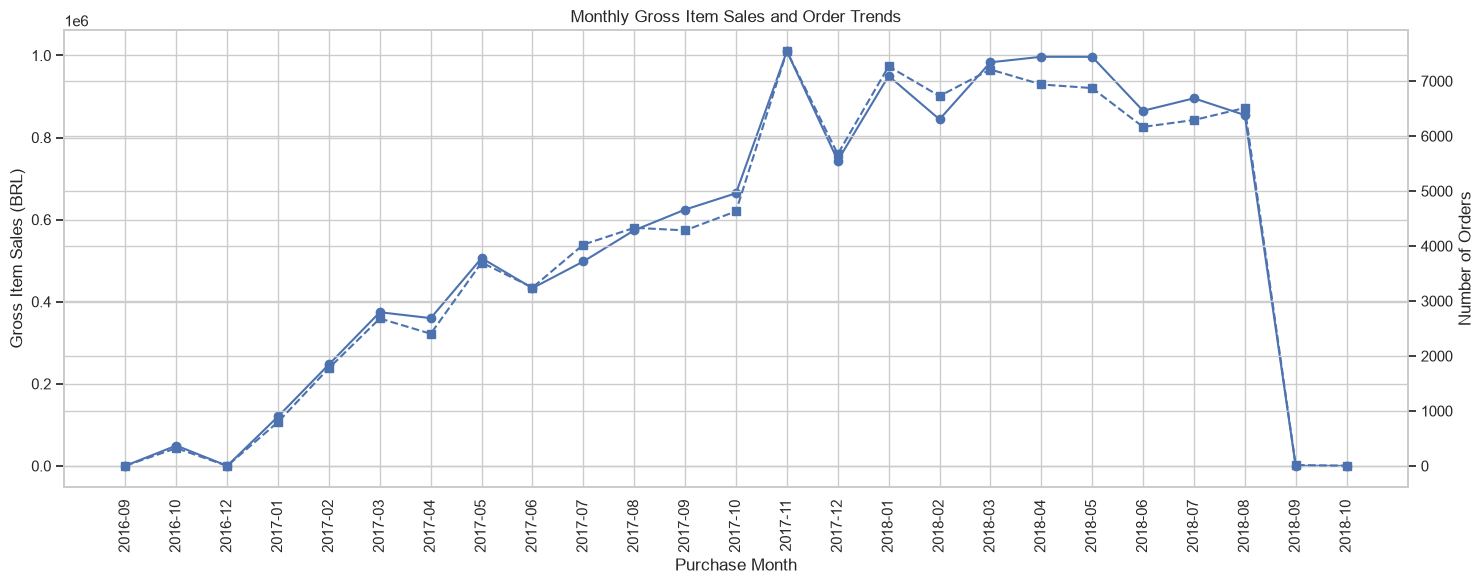

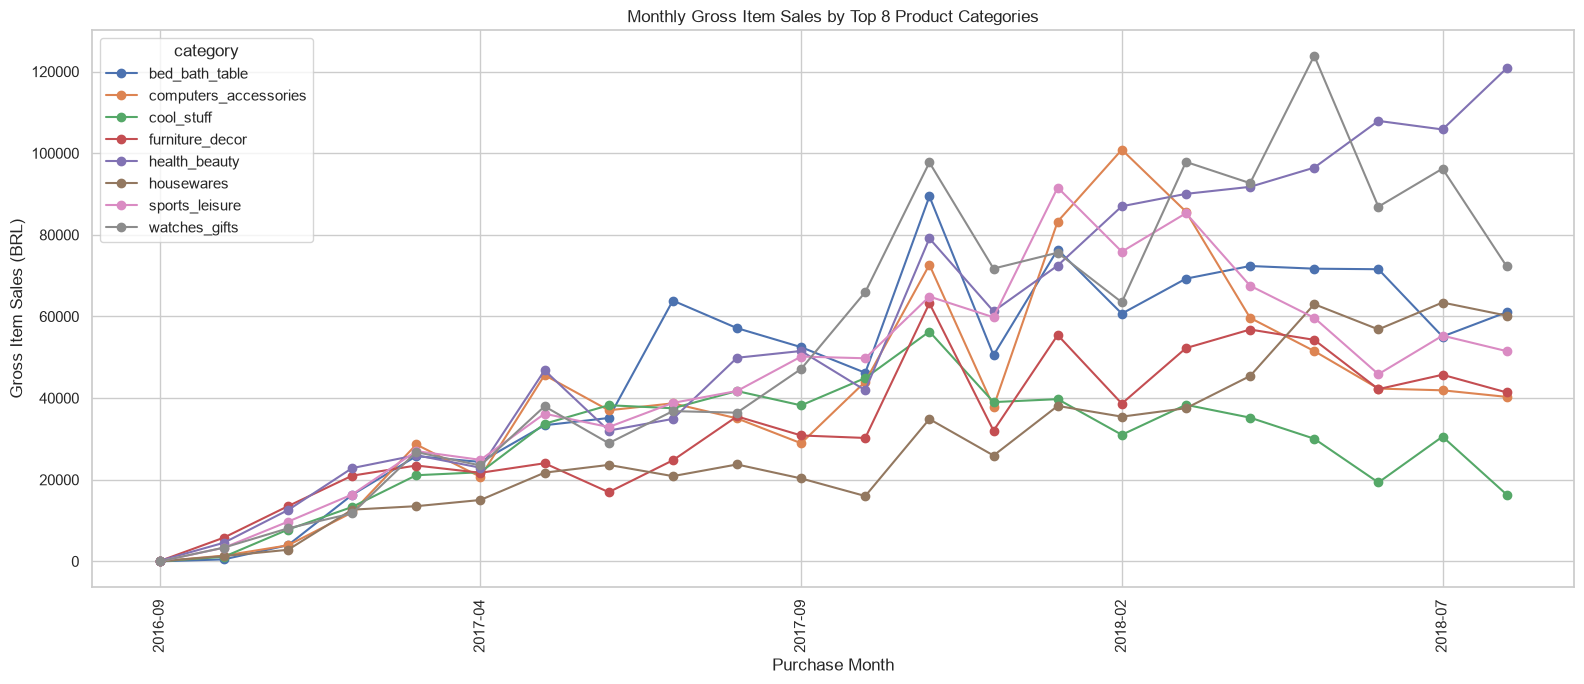

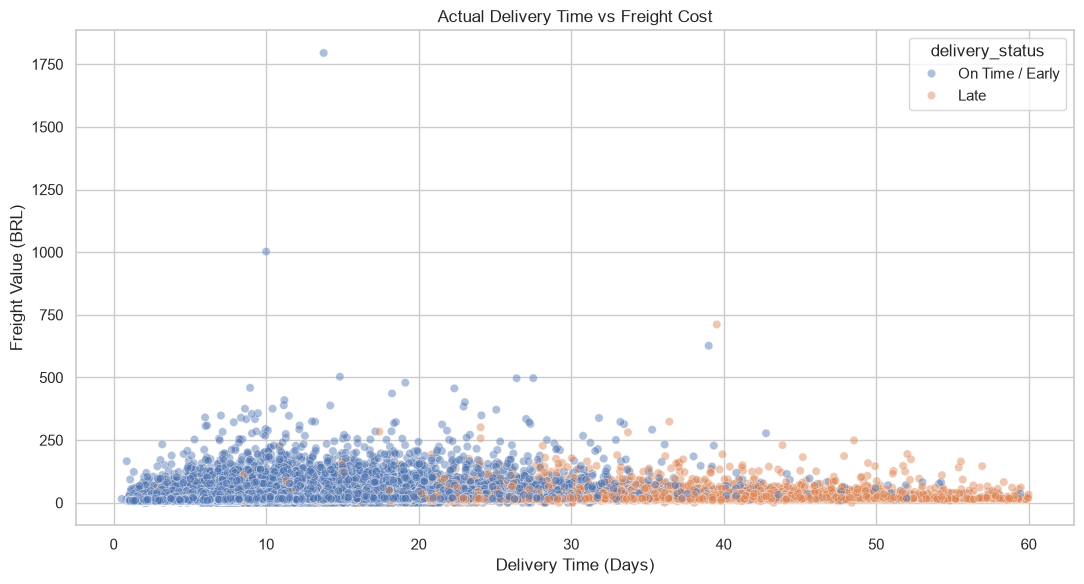

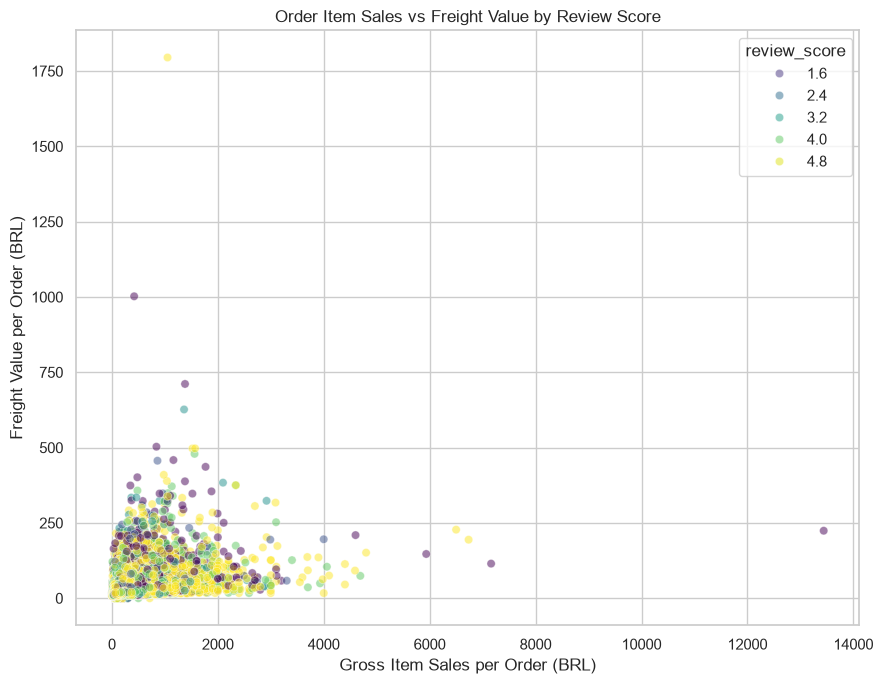

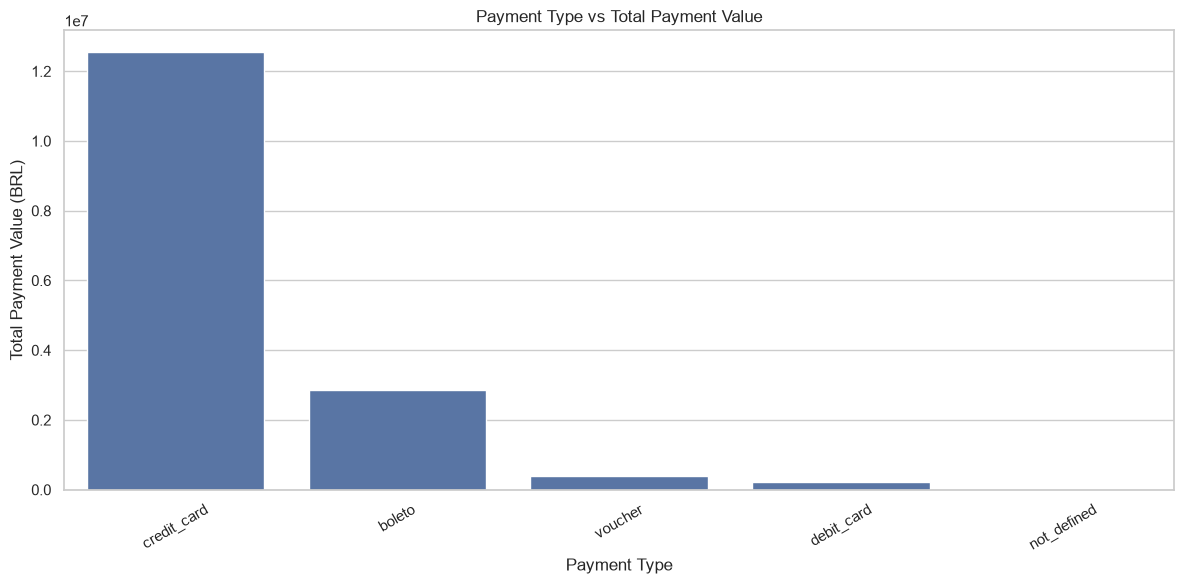

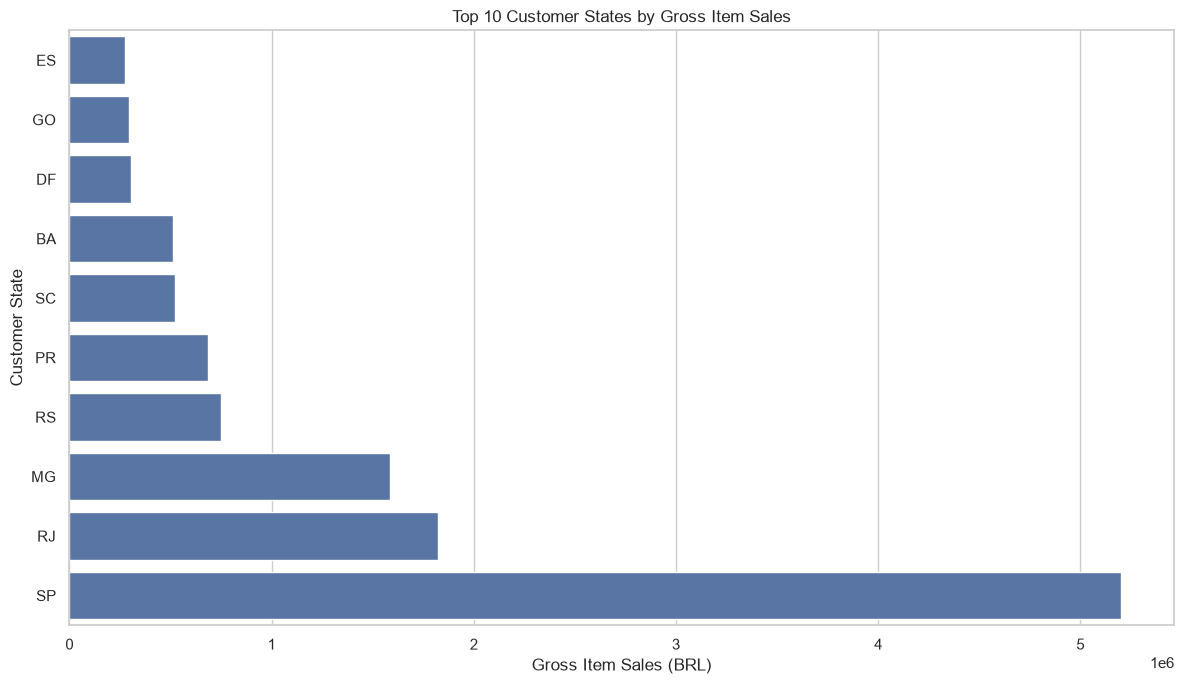

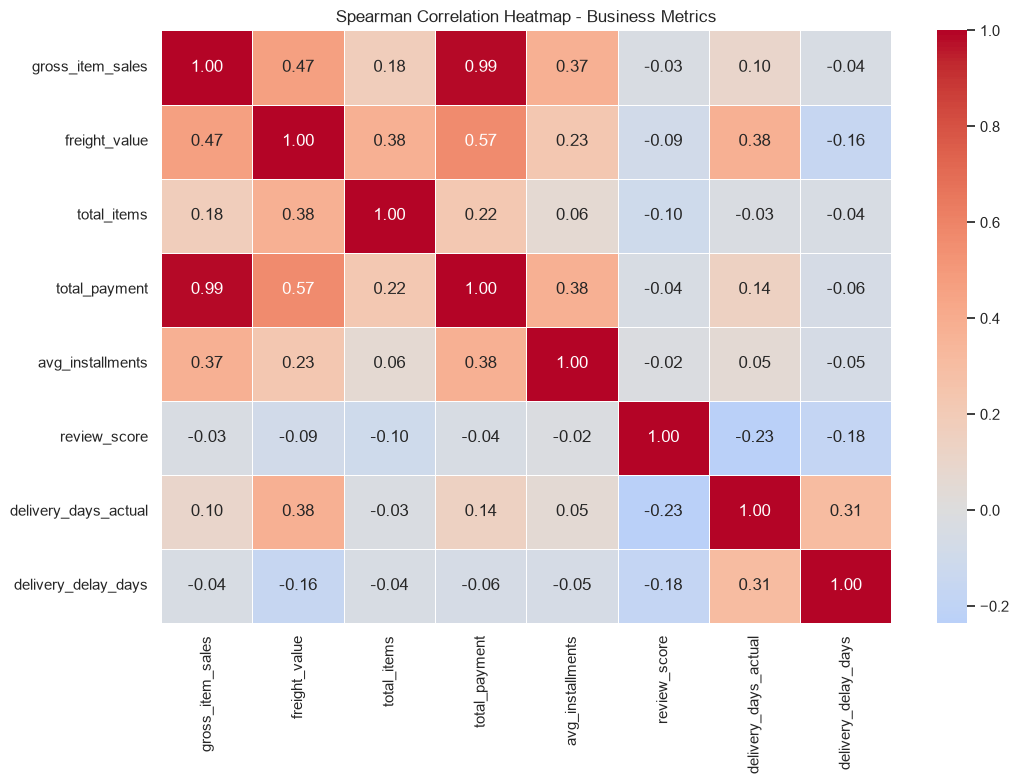


COMMERCECHAIN 360 - MULTIVARIATE EDA RESULTS

1. MONTHLY SALES
purchase_month  gross_item_sales  total_orders
       2017-11        1010271.37          7544
       2018-04         996647.75          6939
       2018-05         996517.68          6873
       2018-03         983213.44          7211
       2018-01         950030.36          7269

2. TOP PRODUCT CATEGORIES
category
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

3. PAYMENT TYPE ANALYSIS
payment_type  transaction_count  total_payment  average_payment  average_installments
 credit_card              76795    12542084.19       163.319021              3.507155
      boleto              19784 

In [8]:

# ============================================================
# COMMERCECHAIN 360
# PHASE 3.3 - MULTIVARIATE EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------------------
# 1. PATHS AND DATA LOADING
# ------------------------------------------------------------

PROJECT_PATH = Path.cwd().parent
DATA_PATH = PROJECT_PATH / "data" / "processed"
OUTPUT_PATH = PROJECT_PATH / "reports" / "EDA" / "Multivariate_Analysis"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

def load_data(filename):
    file_path = DATA_PATH / filename
    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")
    return pd.read_csv(file_path)

orders = load_data("orders_clean.csv")
items = load_data("order_items_clean.csv")
payments = load_data("payments_clean.csv")
reviews = load_data("reviews_clean.csv")
products = load_data("products_clean.csv")
customers = load_data("customers_clean.csv")
sellers = load_data("sellers_clean.csv")
categories = load_data("category_translation_clean.csv")

# ------------------------------------------------------------
# 2. DATETIME CONVERSION
# ------------------------------------------------------------

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

items["price"] = pd.to_numeric(items["price"], errors="coerce")
items["freight_value"] = pd.to_numeric(items["freight_value"], errors="coerce")
payments["payment_value"] = pd.to_numeric(
    payments["payment_value"], errors="coerce"
)
payments["payment_installments"] = pd.to_numeric(
    payments["payment_installments"], errors="coerce"
)

# ------------------------------------------------------------
# 3. CREATE ANALYTICAL TABLES
# ------------------------------------------------------------

# Order-level sales: item price sum, excluding freight
order_sales = (
    items.groupby("order_id", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        freight_value=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
)

# Order-level payment metrics
order_payments = (
    payments.groupby("order_id", as_index=False)
    .agg(
        total_payment=("payment_value", "sum"),
        avg_installments=("payment_installments", "mean")
    )
)

# One review score per order, to avoid multiplying rows
order_reviews = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

# Merge orders with order-level metrics
master = (
    orders.merge(order_sales, on="order_id", how="left")
    .merge(order_payments, on="order_id", how="left")
    .merge(order_reviews, on="order_id", how="left")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
)

master["purchase_month"] = (
    master["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

master["delivery_days_actual"] = (
    master["order_delivered_customer_date"]
    - master["order_purchase_timestamp"]
).dt.total_seconds() / 86400

master["delivery_delay_days"] = (
    master["order_delivered_customer_date"]
    - master["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

master["delivery_status"] = np.select(
    [
        master["order_status"].eq("delivered")
        & master["delivery_delay_days"].notna()
        & master["delivery_delay_days"].le(0),

        master["order_status"].eq("delivered")
        & master["delivery_delay_days"].gt(0)
    ],
    ["On Time / Early", "Late"],
    default="Not Delivered / Unknown"
)

# Category-level item table
items_products = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

items_products = items_products.merge(
    categories[["product_category_name", "product_category_name_english"]],
    on="product_category_name",
    how="left"
)

items_products["category"] = (
    items_products["product_category_name_english"]
    .fillna(items_products["product_category_name"])
    .fillna("Unknown")
)

items_products = items_products.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

items_products["purchase_month"] = (
    pd.to_datetime(
        items_products["order_purchase_timestamp"], errors="coerce"
    ).dt.to_period("M").astype(str)
)

# ------------------------------------------------------------
# 4. MONTHLY SALES AND ORDER TRENDS
# ------------------------------------------------------------

monthly = (
    master.groupby("purchase_month", as_index=False)
    .agg(
        gross_item_sales=("gross_item_sales", "sum"),
        total_orders=("order_id", "nunique")
    )
)

monthly = monthly[monthly["purchase_month"] != "NaT"]

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    monthly["purchase_month"],
    monthly["gross_item_sales"],
    marker="o",
    label="Gross Item Sales"
)
ax1.set_ylabel("Gross Item Sales (BRL)")
ax1.set_xlabel("Purchase Month")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(
    monthly["purchase_month"],
    monthly["total_orders"],
    marker="s",
    linestyle="--",
    label="Orders"
)
ax2.set_ylabel("Number of Orders")

plt.title("Monthly Gross Item Sales and Order Trends")
fig.tight_layout()
plt.savefig(OUTPUT_PATH / "01_monthly_sales_orders.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 5. MONTHLY SALES BY PRODUCT CATEGORY
# ------------------------------------------------------------

category_month = (
    items_products.groupby(
        ["purchase_month", "category"], as_index=False
    )
    .agg(gross_item_sales=("price", "sum"))
)

top_categories = (
    category_month.groupby("category")["gross_item_sales"]
    .sum()
    .nlargest(8)
    .index
)

category_pivot = (
    category_month[category_month["category"].isin(top_categories)]
    .pivot(
        index="purchase_month",
        columns="category",
        values="gross_item_sales"
    )
    .fillna(0)
)

category_pivot = category_pivot.loc[
    category_pivot.index != "NaT"
]

category_pivot.plot(
    figsize=(16, 7),
    marker="o"
)

plt.title("Monthly Gross Item Sales by Top 8 Product Categories")
plt.xlabel("Purchase Month")
plt.ylabel("Gross Item Sales (BRL)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "02_monthly_category_sales.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. DELIVERY TIME VS FREIGHT COST
# ------------------------------------------------------------

delivery_data = master[
    (master["order_status"] == "delivered")
    & master["delivery_days_actual"].notna()
    & master["freight_value"].notna()
].copy()

delivery_data = delivery_data[
    (delivery_data["delivery_days_actual"] >= 0)
    & (delivery_data["delivery_days_actual"] <= 60)
]

if len(delivery_data) > 0:
    plt.figure(figsize=(11, 6))

    sns.scatterplot(
        data=delivery_data,
        x="delivery_days_actual",
        y="freight_value",
        hue="delivery_status",
        alpha=0.45
    )

    plt.title("Actual Delivery Time vs Freight Cost")
    plt.xlabel("Delivery Time (Days)")
    plt.ylabel("Freight Value (BRL)")
    plt.tight_layout()
    plt.savefig(OUTPUT_PATH / "03_delivery_vs_freight.png", bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# 7. PRICE, FREIGHT AND REVIEW SCORE RELATIONSHIPS
# ------------------------------------------------------------

price_review = master[
    ["gross_item_sales", "freight_value", "review_score"]
].dropna()

if len(price_review) > 0:
    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=price_review,
        x="gross_item_sales",
        y="freight_value",
        hue="review_score",
        palette="viridis",
        alpha=0.5
    )

    plt.title("Order Item Sales vs Freight Value by Review Score")
    plt.xlabel("Gross Item Sales per Order (BRL)")
    plt.ylabel("Freight Value per Order (BRL)")
    plt.tight_layout()
    plt.savefig(OUTPUT_PATH / "04_sales_freight_review.png", bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# 8. PAYMENT TYPE AND INSTALLMENT BEHAVIOUR
# ------------------------------------------------------------

payment_analysis = (
    payments.groupby("payment_type", as_index=False)
    .agg(
        transaction_count=("order_id", "count"),
        total_payment=("payment_value", "sum"),
        average_payment=("payment_value", "mean"),
        average_installments=("payment_installments", "mean")
    )
    .sort_values("total_payment", ascending=False)
)

fig, ax1 = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=payment_analysis,
    x="payment_type",
    y="total_payment",
    ax=ax1
)

ax1.set_title("Payment Type vs Total Payment Value")
ax1.set_xlabel("Payment Type")
ax1.set_ylabel("Total Payment Value (BRL)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "05_payment_type_analysis.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 9. CUSTOMER STATE: ORDER VOLUME AND SALES
# ------------------------------------------------------------

state_analysis = (
    master.groupby("customer_state", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        gross_item_sales=("gross_item_sales", "sum"),
        average_order_value=("gross_item_sales", "mean")
    )
    .sort_values("gross_item_sales", ascending=False)
)

top_states = state_analysis.head(10).sort_values(
    "gross_item_sales", ascending=True
)

fig, ax1 = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=top_states,
    x="gross_item_sales",
    y="customer_state",
    ax=ax1
)

plt.title("Top 10 Customer States by Gross Item Sales")
plt.xlabel("Gross Item Sales (BRL)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "06_state_sales_analysis.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 10. MULTIVARIATE CORRELATION HEATMAP
# ------------------------------------------------------------

numeric_columns = [
    "gross_item_sales",
    "freight_value",
    "total_items",
    "total_payment",
    "avg_installments",
    "review_score",
    "delivery_days_actual",
    "delivery_delay_days"
]

correlation_data = master[numeric_columns].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Spearman Correlation Heatmap - Business Metrics")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "07_business_metrics_correlation.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 11. EXPORT ANALYTICAL SUMMARIES
# ------------------------------------------------------------

summary_file = OUTPUT_PATH / "CommerceChain_Multivariate_Analysis.xlsx"

with pd.ExcelWriter(summary_file, engine="openpyxl") as writer:
    monthly.to_excel(writer, sheet_name="Monthly_Trends", index=False)
    category_month.to_excel(writer, sheet_name="Category_Monthly", index=False)
    payment_analysis.to_excel(writer, sheet_name="Payment_Analysis", index=False)
    state_analysis.to_excel(writer, sheet_name="State_Analysis", index=False)
    correlation_data.to_excel(writer, sheet_name="Correlation")

# ------------------------------------------------------------
# 12. AUTOMATED BUSINESS INSIGHTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("COMMERCECHAIN 360 - MULTIVARIATE EDA RESULTS")
print("=" * 65)

print("\n1. MONTHLY SALES")
print(monthly.sort_values(
    "gross_item_sales", ascending=False
).head(5).to_string(index=False))

print("\n2. TOP PRODUCT CATEGORIES")
print(
    items_products.groupby("category")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n3. PAYMENT TYPE ANALYSIS")
print(payment_analysis.to_string(index=False))

print("\n4. TOP CUSTOMER STATES")
print(state_analysis.head(10).to_string(index=False))

print("\n5. DELIVERY PERFORMANCE")
print(master["delivery_status"].value_counts())

print("\n6. CORRELATION WITH DELIVERY DELAY")
print(
    correlation_data["delivery_delay_days"]
    .sort_values(ascending=False)
)

print("\n7. REVIEW SCORE")
print("Average review score:", round(master["review_score"].mean(), 2))

print("\n" + "=" * 65)
print("MULTIVARIATE ANALYSIS COMPLETED SUCCESSFULLY")
print("Charts and Excel report saved at:")
print(OUTPUT_PATH)
print("=" * 65)


In [9]:

# ============================================================
# COMMERCECHAIN 360
# PHASE 3.4 - BUSINESS PERFORMANCE & KPI ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_PATH = Path.cwd().parent
DATA_PATH = PROJECT_PATH / "data" / "processed"
OUTPUT_PATH = PROJECT_PATH / "reports" / "EDA" / "Business_Performance"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

def load_data(filename):
    path = DATA_PATH / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path)

# ------------------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------------------

orders = load_data("orders_clean.csv")
items = load_data("order_items_clean.csv")
payments = load_data("payments_clean.csv")
reviews = load_data("reviews_clean.csv")
products = load_data("products_clean.csv")
customers = load_data("customers_clean.csv")
sellers = load_data("sellers_clean.csv")
categories = load_data("category_translation_clean.csv")

# ------------------------------------------------------------
# 3. DATA TYPE CONVERSION
# ------------------------------------------------------------

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"], errors="coerce"
)

items["price"] = pd.to_numeric(items["price"], errors="coerce")
items["freight_value"] = pd.to_numeric(items["freight_value"], errors="coerce")
payments["payment_value"] = pd.to_numeric(
    payments["payment_value"], errors="coerce"
)

# ------------------------------------------------------------
# 4. ORDER-LEVEL BUSINESS TABLE
# ------------------------------------------------------------

order_sales = (
    items.groupby("order_id", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        freight_value=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
)

order_payment = (
    payments.groupby("order_id", as_index=False)
    .agg(total_payment=("payment_value", "sum"))
)

order_review = (
    reviews.groupby("order_id", as_index=False)
    .agg(avg_review_score=("review_score", "mean"))
)

business = (
    orders.merge(order_sales, on="order_id", how="left")
    .merge(order_payment, on="order_id", how="left")
    .merge(order_review, on="order_id", how="left")
    .merge(
        customers[["customer_id", "customer_unique_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
)

business["purchase_month"] = (
    business["order_purchase_timestamp"].dt.to_period("M")
)

business["delivery_delay_days"] = (
    business["order_delivered_customer_date"]
    - business["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

business["delivery_status"] = np.select(
    [
        business["order_status"].eq("delivered")
        & business["delivery_delay_days"].notna()
        & business["delivery_delay_days"].le(0),

        business["order_status"].eq("delivered")
        & business["delivery_delay_days"].gt(0)
    ],
    ["On Time / Early", "Late"],
    default="Not Delivered / Unknown"
)

# ------------------------------------------------------------
# 5. OVERALL BUSINESS KPIs
# ------------------------------------------------------------

total_orders = business["order_id"].nunique()

delivered_orders = business.loc[
    business["order_status"].eq("delivered"), "order_id"
].nunique()

gross_item_sales = business["gross_item_sales"].sum()

total_payment_value = business["total_payment"].sum()

unique_customers = business["customer_unique_id"].nunique()

average_order_value = (
    business["gross_item_sales"].sum()
    / business["order_id"].nunique()
)

delivered_with_known_dates = business[
    business["order_status"].eq("delivered")
    & business["delivery_delay_days"].notna()
]

on_time_orders = delivered_with_known_dates[
    delivered_with_known_dates["delivery_delay_days"] <= 0
]["order_id"].nunique()

late_orders = delivered_with_known_dates[
    delivered_with_known_dates["delivery_delay_days"] > 0
]["order_id"].nunique()

on_time_delivery_rate = (
    on_time_orders / len(delivered_with_known_dates) * 100
    if len(delivered_with_known_dates) else np.nan
)

late_delivery_rate = (
    late_orders / len(delivered_with_known_dates) * 100
    if len(delivered_with_known_dates) else np.nan
)

average_review = business["avg_review_score"].mean()

kpi_report = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Delivered Orders",
        "Gross Item Sales (BRL)",
        "Recorded Payment Value (BRL)",
        "Unique Customers",
        "Average Order Value (BRL)",
        "On-Time Delivery Rate (%)",
        "Late Delivery Rate (%)",
        "Average Review Score"
    ],
    "Value": [
        total_orders,
        delivered_orders,
        gross_item_sales,
        total_payment_value,
        unique_customers,
        average_order_value,
        on_time_delivery_rate,
        late_delivery_rate,
        average_review
    ]
})

# ------------------------------------------------------------
# 6. MONTHLY SALES GROWTH
# ------------------------------------------------------------

monthly_sales = (
    business.dropna(subset=["purchase_month"])
    .groupby("purchase_month", as_index=False)
    .agg(
        gross_item_sales=("gross_item_sales", "sum"),
        total_orders=("order_id", "nunique")
    )
)

monthly_sales["month"] = monthly_sales["purchase_month"].astype(str)

monthly_sales["sales_growth_pct"] = (
    monthly_sales["gross_item_sales"].pct_change() * 100
)

monthly_sales["order_growth_pct"] = (
    monthly_sales["total_orders"].pct_change() * 100
)

# ------------------------------------------------------------
# 7. CUSTOMER REPEAT PURCHASE ANALYSIS
# ------------------------------------------------------------

customer_orders = (
    business.groupby("customer_unique_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        customer_sales=("gross_item_sales", "sum")
    )
)

customer_orders["customer_type"] = np.where(
    customer_orders["order_count"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_segment = (
    customer_orders.groupby("customer_type", as_index=False)
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_sales=("customer_sales", "sum"),
        average_orders=("order_count", "mean")
    )
)

customer_segment["customer_percentage"] = (
    customer_segment["customers"]
    / customer_segment["customers"].sum() * 100
)

# ------------------------------------------------------------
# 8. PRODUCT CATEGORY PERFORMANCE
# ------------------------------------------------------------

item_category = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

item_category = item_category.merge(
    categories[["product_category_name", "product_category_name_english"]],
    on="product_category_name",
    how="left"
)

item_category["category"] = (
    item_category["product_category_name_english"]
    .fillna(item_category["product_category_name"])
    .fillna("Unknown")
)

category_performance = (
    item_category.groupby("category", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        units_sold=("order_item_id", "count"),
        average_item_price=("price", "mean"),
        total_freight=("freight_value", "sum")
    )
    .sort_values("gross_item_sales", ascending=False)
)

category_performance["sales_contribution_pct"] = (
    category_performance["gross_item_sales"]
    / category_performance["gross_item_sales"].sum() * 100
)

# ------------------------------------------------------------
# 9. SELLER PERFORMANCE
# ------------------------------------------------------------

seller_performance = items.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left"
)

seller_performance = (
    seller_performance.groupby(
        ["seller_id", "seller_state"], as_index=False
    )
    .agg(
        gross_item_sales=("price", "sum"),
        units_sold=("order_item_id", "count"),
        average_item_price=("price", "mean"),
        total_freight=("freight_value", "sum"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("gross_item_sales", ascending=False)
)

# ------------------------------------------------------------
# 10. CUSTOMER SATISFACTION
# ------------------------------------------------------------

review_performance = (
    reviews.groupby("review_score", as_index=False)
    .agg(review_count=("review_id", "count"))
    .sort_values("review_score")
)

review_performance["review_share_pct"] = (
    review_performance["review_count"]
    / review_performance["review_count"].sum() * 100
)

# ------------------------------------------------------------
# 11. DELIVERY PERFORMANCE
# ------------------------------------------------------------

delivery_performance = (
    business.groupby("delivery_status", as_index=False)
    .agg(total_orders=("order_id", "nunique"))
)

delivery_performance["order_share_pct"] = (
    delivery_performance["total_orders"]
    / delivery_performance["total_orders"].sum() * 100
)

delivery_time = business.loc[
    business["order_status"].eq("delivered")
].copy()

delivery_time["actual_delivery_days"] = (
    delivery_time["order_delivered_customer_date"]
    - delivery_time["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_time = delivery_time[
    delivery_time["actual_delivery_days"].between(0, 90)
]

# ------------------------------------------------------------
# 12. BUSINESS INSIGHTS
# ------------------------------------------------------------

top_category = category_performance.iloc[0]
top_seller = seller_performance.iloc[0]
top_month = monthly_sales.loc[
    monthly_sales["gross_item_sales"].idxmax()
]

repeat_share = customer_segment.loc[
    customer_segment["customer_type"].eq("Repeat Customer"),
    "customer_percentage"
].sum()

insights = [
    f"Total orders analysed: {total_orders:,}",
    f"Gross item sales: BRL {gross_item_sales:,.2f}",
    f"Average order value: BRL {average_order_value:,.2f}",
    f"Top category: {top_category['category']} "
    f"(BRL {top_category['gross_item_sales']:,.2f})",
    f"Top seller ID: {top_seller['seller_id']} "
    f"(BRL {top_seller['gross_item_sales']:,.2f})",
    f"Best sales month: {top_month['month']}",
    f"Repeat customer share: {repeat_share:.2f}%",
    f"On-time delivery rate: {on_time_delivery_rate:.2f}%",
    f"Late delivery rate: {late_delivery_rate:.2f}%",
    f"Average review score: {average_review:.2f}/5"
]

# ------------------------------------------------------------
# 13. EXPORT ALL REPORTS
# ------------------------------------------------------------

with pd.ExcelWriter(
    OUTPUT_PATH / "CommerceChain_Business_KPI_Report.xlsx",
    engine="openpyxl"
) as writer:

    kpi_report.to_excel(writer, sheet_name="Business_KPIs", index=False)
    monthly_sales.to_excel(writer, sheet_name="Monthly_Sales", index=False)
    customer_segment.to_excel(writer, sheet_name="Customer_Segments", index=False)
    category_performance.to_excel(writer, sheet_name="Category_Performance", index=False)
    seller_performance.to_excel(writer, sheet_name="Seller_Performance", index=False)
    review_performance.to_excel(writer, sheet_name="Review_Analysis", index=False)
    delivery_performance.to_excel(writer, sheet_name="Delivery_Performance", index=False)

pd.DataFrame({"Business Insight": insights}).to_csv(
    OUTPUT_PATH / "Business_Insights.csv",
    index=False
)

# ------------------------------------------------------------
# 14. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("COMMERCECHAIN 360 - BUSINESS PERFORMANCE REPORT")
print("=" * 65)

print("\nOVERALL BUSINESS KPIs")
print(kpi_report.to_string(index=False))

print("\nMONTHLY SALES GROWTH")
print(monthly_sales.tail(12).to_string(index=False))

print("\nCUSTOMER SEGMENTATION")
print(customer_segment.to_string(index=False))

print("\nTOP 10 PRODUCT CATEGORIES")
print(category_performance.head(10).to_string(index=False))

print("\nTOP 10 SELLERS")
print(seller_performance.head(10).to_string(index=False))

print("\nDELIVERY PERFORMANCE")
print(delivery_performance.to_string(index=False))

print("\nBUSINESS INSIGHTS")
for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

print("\n" + "=" * 65)
print("BUSINESS PERFORMANCE ANALYSIS COMPLETED")
print("Reports saved at:", OUTPUT_PATH)
print("=" * 65)



COMMERCECHAIN 360 - BUSINESS PERFORMANCE REPORT

OVERALL BUSINESS KPIs
                         KPI        Value
                Total Orders 9.944100e+04
            Delivered Orders 9.647800e+04
      Gross Item Sales (BRL) 1.359164e+07
Recorded Payment Value (BRL) 1.600887e+07
            Unique Customers 9.609600e+04
   Average Order Value (BRL) 1.366805e+02
   On-Time Delivery Rate (%) 9.188763e+01
      Late Delivery Rate (%) 8.112367e+00
        Average Review Score 4.086793e+00

MONTHLY SALES GROWTH
purchase_month  gross_item_sales  total_orders   month  sales_growth_pct  order_growth_pct
       2017-11        1010271.37          7544 2017-11         52.099039         62.902181
       2017-12         743914.17          5673 2017-12        -26.364916        -24.801166
       2018-01         950030.36          7269 2018-01         27.706985         28.133263
       2018-02         844178.71          6728 2018-02        -11.141923         -7.442564
       2018-03         983213.4

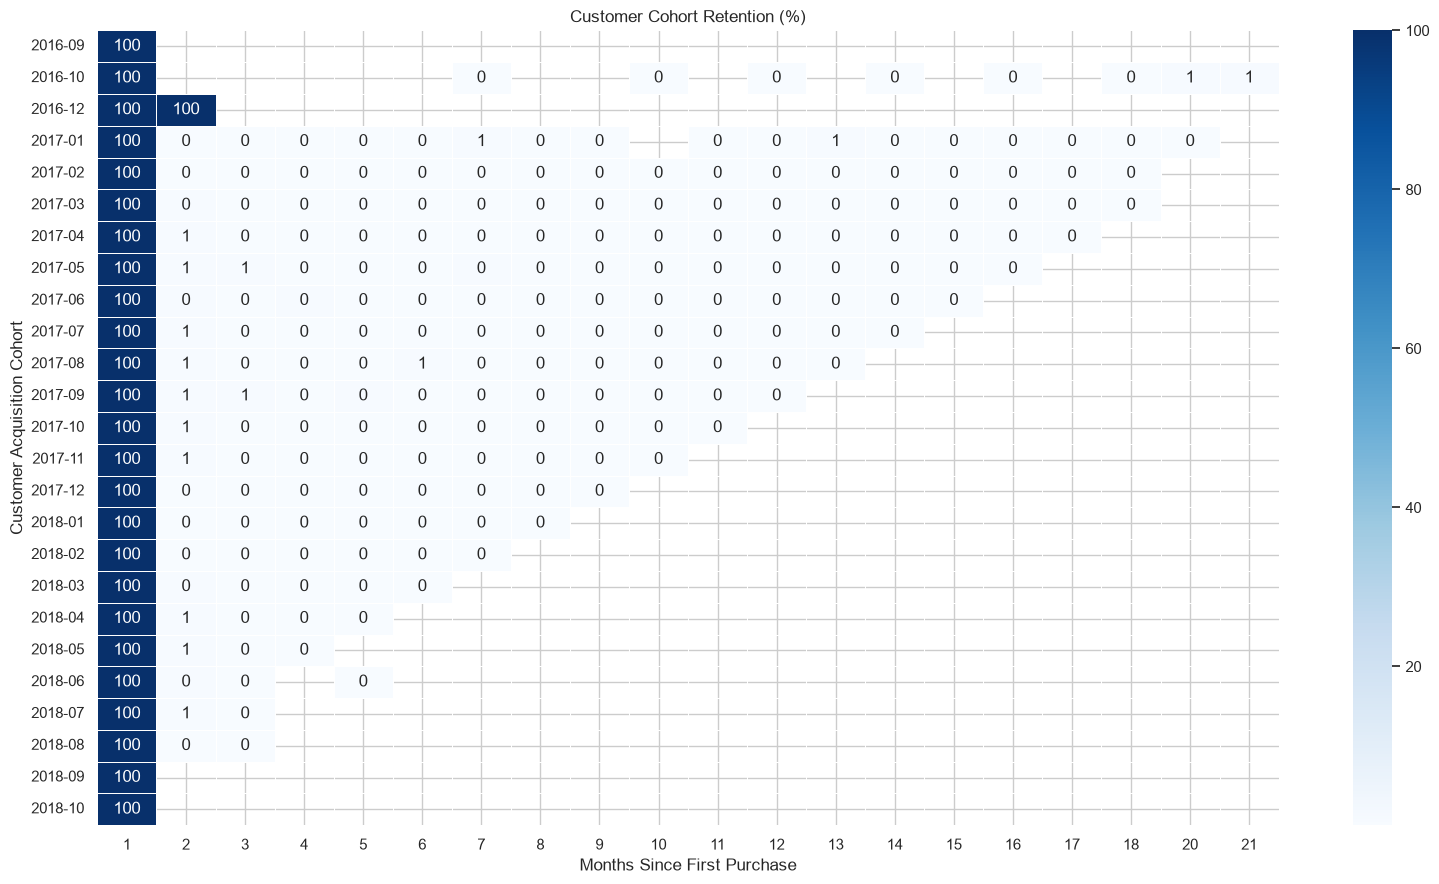

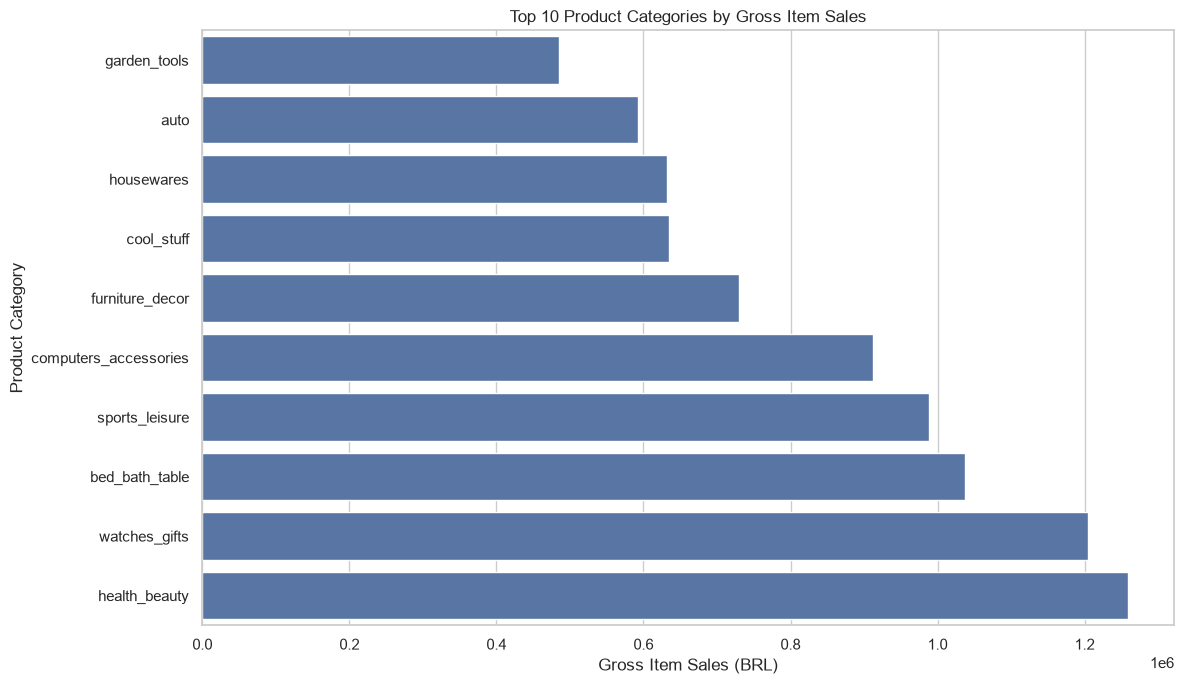

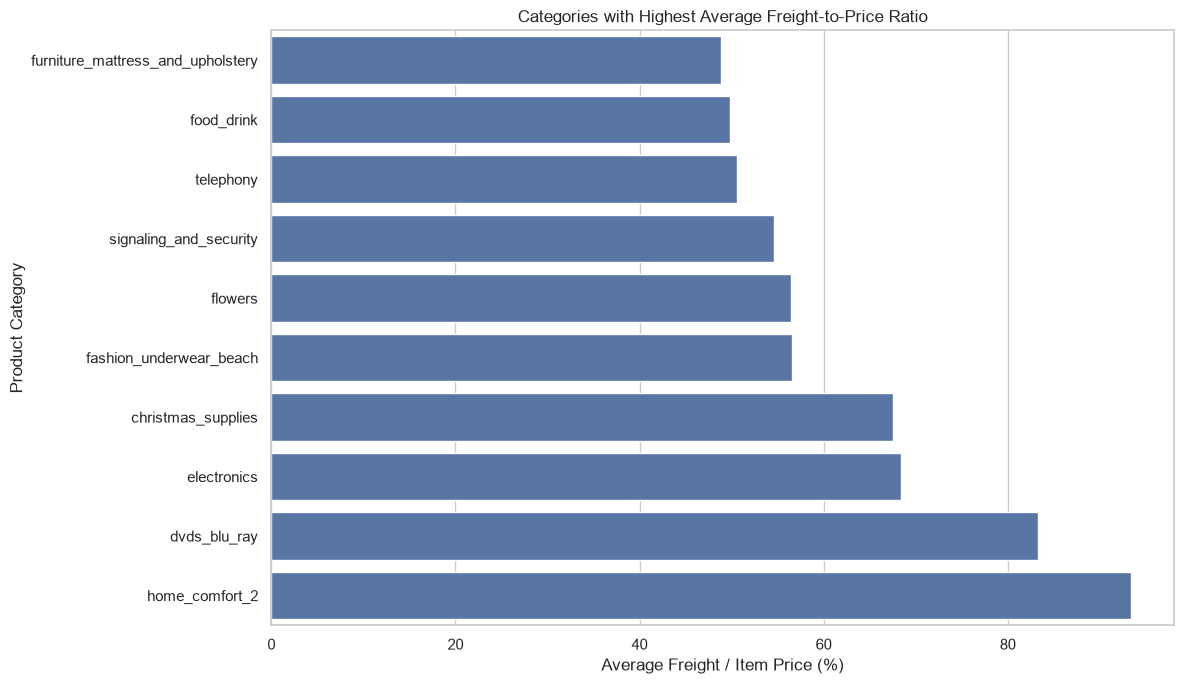

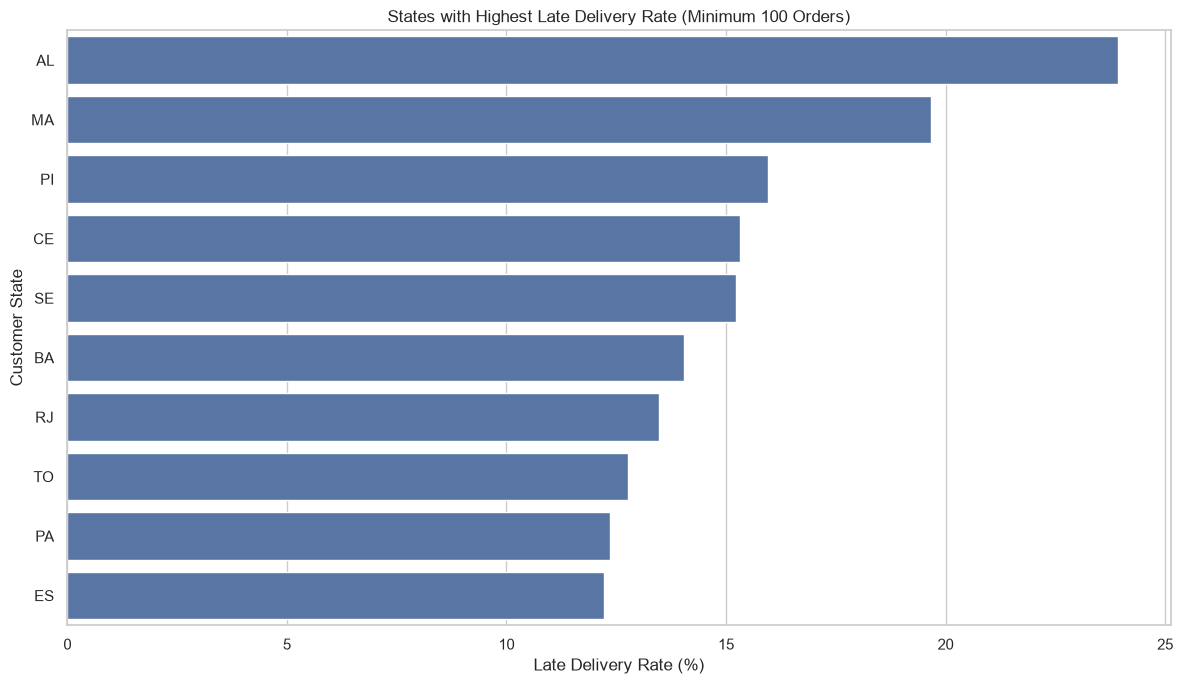


COMMERCECHAIN 360 - CUSTOMER, PRODUCT & LOGISTICS DEEP-DIVE

1. CUSTOMER RFM SEGMENTATION
         customer_segment  customers  average_recency_days  average_frequency  total_monetary  average_monetary  customer_share_pct
                  At Risk      22975            445.693232           1.049576      3292419.07        143.304421           23.908383
Inactive / Low Engagement      15463            446.735627           1.000000      2160899.59        139.746465           16.091200
   Loyal / Best Customers      15376            139.836173           1.098075      2333701.44        151.775588           16.000666
      Potential Loyalists      19306            219.007096           1.036155      2650574.63        137.292791           20.090326
        Regular Customers      22976            183.687239           1.000000      3154048.97        137.275808           23.909424

2. TOP 10 PRODUCT CATEGORIES
             category  gross_item_sales  units_sold  average_item_price  freight_value 

In [10]:

# ============================================================
# COMMERCECHAIN 360
# PHASE 3.5 - CUSTOMER, PRODUCT & LOGISTICS DEEP-DIVE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

# ------------------------------------------------------------
# 1. PATHS AND DATA LOADING
# ------------------------------------------------------------

PROJECT_PATH = Path.cwd().parent
DATA_PATH = PROJECT_PATH / "data" / "processed"
OUTPUT_PATH = PROJECT_PATH / "reports" / "EDA" / "Deep_Dive_Analysis"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

def load_data(filename):
    path = DATA_PATH / filename
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)

orders = load_data("orders_clean.csv")
items = load_data("order_items_clean.csv")
customers = load_data("customers_clean.csv")
products = load_data("products_clean.csv")
sellers = load_data("sellers_clean.csv")
reviews = load_data("reviews_clean.csv")
categories = load_data("category_translation_clean.csv")

# ------------------------------------------------------------
# 2. DATA TYPE CONVERSION
# ------------------------------------------------------------

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"], errors="coerce"
)

items["price"] = pd.to_numeric(items["price"], errors="coerce")
items["freight_value"] = pd.to_numeric(
    items["freight_value"], errors="coerce"
)

reviews["review_score"] = pd.to_numeric(
    reviews["review_score"], errors="coerce"
)

# ------------------------------------------------------------
# 3. BUILD ORDER-LEVEL CUSTOMER TABLE
# ------------------------------------------------------------

order_sales = (
    items.groupby("order_id", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        freight_value=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
)

customer_data = (
    orders.merge(
        order_sales,
        on="order_id",
        how="left"
    )
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
)

customer_data["gross_item_sales"] = (
    customer_data["gross_item_sales"].fillna(0)
)

# ------------------------------------------------------------
# 4. CUSTOMER RFM SEGMENTATION
# ------------------------------------------------------------

# Use a fixed reference date one day after the latest
# purchase timestamp to make the analysis reproducible.

reference_date = (
    customer_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    customer_data.dropna(
        subset=["customer_unique_id", "order_purchase_timestamp"]
    )
    .groupby("customer_unique_id")
    .agg(
        recency=("order_purchase_timestamp",
                 lambda x: (reference_date - x.max()).days),
        frequency=("order_id", "nunique"),
        monetary=("gross_item_sales", "sum")
    )
    .reset_index()
)

# Rank customers into five groups.
# Handle tied values safely with rank(method="first").

rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm["customer_segment"] = np.select(
    [
        (rfm["R_score"] >= 4) & (rfm["F_score"] >= 4),
        (rfm["R_score"] >= 3) & (rfm["F_score"] >= 3),
        (rfm["R_score"] <= 2) & (rfm["F_score"] >= 3),
        (rfm["R_score"] <= 2) & (rfm["F_score"] <= 2),
    ],
    [
        "Loyal / Best Customers",
        "Potential Loyalists",
        "At Risk",
        "Inactive / Low Engagement"
    ],
    default="Regular Customers"
)

rfm_summary = (
    rfm.groupby("customer_segment", as_index=False)
    .agg(
        customers=("customer_unique_id", "count"),
        average_recency_days=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        total_monetary=("monetary", "sum"),
        average_monetary=("monetary", "mean")
    )
)

rfm_summary["customer_share_pct"] = (
    rfm_summary["customers"] / rfm["customer_unique_id"].nunique() * 100
)

# ------------------------------------------------------------
# 5. CUSTOMER COHORT ANALYSIS
# ------------------------------------------------------------

cohort_data = customer_data.dropna(
    subset=["customer_unique_id", "order_purchase_timestamp"]
).copy()

cohort_data["order_month"] = (
    cohort_data["order_purchase_timestamp"].dt.to_period("M")
)

first_purchase = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .min()
    .rename("cohort_month")
)

cohort_data = cohort_data.join(
    first_purchase,
    on="customer_unique_id"
)

cohort_data["cohort_index"] = (
    (cohort_data["order_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    + cohort_data["order_month"].dt.month
    - cohort_data["cohort_month"].dt.month
    + 1
)

cohort_counts = (
    cohort_data.groupby(
        ["cohort_month", "cohort_index"]
    )["customer_unique_id"]
    .nunique()
    .reset_index(name="customers")
)

cohort_pivot = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customers"
)

cohort_sizes = cohort_pivot.iloc[:, 0]

cohort_retention = cohort_pivot.divide(
    cohort_sizes, axis=0
) * 100

plt.figure(figsize=(16, 9))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "01_customer_cohort_retention.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 6. PRODUCT CATEGORY PERFORMANCE
# ------------------------------------------------------------

product_analysis = (
    items.merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .merge(
        categories[
            ["product_category_name", "product_category_name_english"]
        ],
        on="product_category_name",
        how="left"
    )
)

product_analysis["category"] = (
    product_analysis["product_category_name_english"]
    .fillna(product_analysis["product_category_name"])
    .fillna("Unknown")
)

category_summary = (
    product_analysis.groupby("category", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        units_sold=("order_item_id", "count"),
        average_item_price=("price", "mean"),
        freight_value=("freight_value", "sum"),
        unique_products=("product_id", "nunique")
    )
    .sort_values("gross_item_sales", ascending=False)
)

category_summary["sales_contribution_pct"] = (
    category_summary["gross_item_sales"]
    / category_summary["gross_item_sales"].sum() * 100
)

category_summary["cumulative_sales_pct"] = (
    category_summary["sales_contribution_pct"].cumsum()
)

top_categories = category_summary.head(10).sort_values(
    "gross_item_sales"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_categories,
    x="gross_item_sales",
    y="category"
)

plt.title("Top 10 Product Categories by Gross Item Sales")
plt.xlabel("Gross Item Sales (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "02_top_product_categories.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. FREIGHT COST ANALYSIS
# ------------------------------------------------------------

freight_analysis = product_analysis.copy()

freight_analysis["freight_to_price_ratio_pct"] = np.where(
    freight_analysis["price"] > 0,
    freight_analysis["freight_value"]
    / freight_analysis["price"] * 100,
    np.nan
)

freight_by_category = (
    freight_analysis.groupby("category", as_index=False)
    .agg(
        gross_item_sales=("price", "sum"),
        total_freight=("freight_value", "sum"),
        average_freight_ratio_pct=(
            "freight_to_price_ratio_pct", "mean"
        ),
        units_sold=("order_item_id", "count")
    )
)

freight_by_category = freight_by_category.sort_values(
    "average_freight_ratio_pct", ascending=False
)

top_freight_categories = freight_by_category.head(10).sort_values(
    "average_freight_ratio_pct"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_freight_categories,
    x="average_freight_ratio_pct",
    y="category"
)

plt.title("Categories with Highest Average Freight-to-Price Ratio")
plt.xlabel("Average Freight / Item Price (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "03_freight_ratio_by_category.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 8. DELIVERY PERFORMANCE BY CUSTOMER STATE
# ------------------------------------------------------------

delivery_data = customer_data[
    customer_data["order_status"].eq("delivered")
].copy()

delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_data = delivery_data.dropna(
    subset=["delivery_delay_days", "customer_state"]
)

delivery_data["delivery_result"] = np.where(
    delivery_data["delivery_delay_days"] > 0,
    "Late",
    "On Time / Early"
)

state_delivery = (
    delivery_data.groupby("customer_state", as_index=False)
    .agg(
        delivered_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_result",
            lambda x: (x == "Late").sum()
        ),
        average_delay_days=("delivery_delay_days", "mean")
    )
)

state_delivery["late_delivery_rate_pct"] = (
    state_delivery["late_orders"]
    / state_delivery["delivered_orders"] * 100
)

# Minimum sample threshold prevents over-interpreting
# states with very few delivered orders.

state_delivery_reliable = state_delivery[
    state_delivery["delivered_orders"] >= 100
].sort_values(
    "late_delivery_rate_pct", ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_delivery_reliable.head(10),
    x="late_delivery_rate_pct",
    y="customer_state"
)

plt.title("States with Highest Late Delivery Rate (Minimum 100 Orders)")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "04_late_delivery_by_state.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 9. SELLER DELIVERY PERFORMANCE
# ------------------------------------------------------------

seller_orders = (
    items[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(
        orders[
            [
                "order_id",
                "order_status",
                "order_delivered_customer_date",
                "order_estimated_delivery_date"
            ]
        ],
        on="order_id",
        how="left"
    )
)

seller_orders["delivery_delay_days"] = (
    pd.to_datetime(
        seller_orders["order_delivered_customer_date"],
        errors="coerce"
    )
    - pd.to_datetime(
        seller_orders["order_estimated_delivery_date"],
        errors="coerce"
    )
).dt.total_seconds() / 86400

seller_orders = seller_orders[
    seller_orders["order_status"].eq("delivered")
    & seller_orders["delivery_delay_days"].notna()
].copy()

seller_orders["is_late"] = (
    seller_orders["delivery_delay_days"] > 0
).astype(int)

seller_delivery = (
    seller_orders.groupby("seller_id", as_index=False)
    .agg(
        delivered_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum"),
        average_delay_days=("delivery_delay_days", "mean")
    )
)

seller_delivery["late_delivery_rate_pct"] = (
    seller_delivery["late_orders"]
    / seller_delivery["delivered_orders"] * 100
)

seller_delivery_reliable = seller_delivery[
    seller_delivery["delivered_orders"] >= 20
].sort_values(
    "late_delivery_rate_pct", ascending=False
)

# ------------------------------------------------------------
# 10. EXPORT ANALYSIS
# ------------------------------------------------------------

with pd.ExcelWriter(
    OUTPUT_PATH / "CommerceChain_Deep_Dive_Report.xlsx",
    engine="openpyxl"
) as writer:

    rfm.to_excel(writer, sheet_name="Customer_RFM", index=False)
    rfm_summary.to_excel(writer, sheet_name="RFM_Summary", index=False)
    cohort_counts.to_excel(writer, sheet_name="Cohort_Counts", index=False)
    cohort_retention.to_excel(writer, sheet_name="Cohort_Retention")
    category_summary.to_excel(writer, sheet_name="Category_Analysis", index=False)
    freight_by_category.to_excel(writer, sheet_name="Freight_Analysis", index=False)
    state_delivery.to_excel(writer, sheet_name="State_Delivery", index=False)
    seller_delivery.to_excel(writer, sheet_name="Seller_Delivery", index=False)

# ------------------------------------------------------------
# 11. DISPLAY BUSINESS FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMMERCECHAIN 360 - CUSTOMER, PRODUCT & LOGISTICS DEEP-DIVE")
print("=" * 70)

print("\n1. CUSTOMER RFM SEGMENTATION")
print(rfm_summary.to_string(index=False))

print("\n2. TOP 10 PRODUCT CATEGORIES")
print(category_summary.head(10).to_string(index=False))

print("\n3. TOP 10 CATEGORIES BY FREIGHT-TO-PRICE RATIO")
print(freight_by_category.head(10).to_string(index=False))

print("\n4. STATES WITH HIGHEST LATE DELIVERY RATE")
print(state_delivery_reliable.head(10).to_string(index=False))

print("\n5. SELLERS WITH HIGHEST LATE DELIVERY RATE")
print(seller_delivery_reliable.head(10).to_string(index=False))

print("\n6. COHORT RETENTION TABLE")
print(cohort_retention.head(12).round(2).to_string())

print("\n" + "=" * 70)
print("DEEP-DIVE ANALYSIS COMPLETED SUCCESSFULLY")
print("Reports saved at:", OUTPUT_PATH)
print("=" * 70)
